# Forgetting through the lens of internal features

The LMEnt setup shows a **learning-forgetting** phenomenon: as training proceeds a
fact can be recalled correctly, then lost, then relearned. This notebook asks
*what happens inside the model* when a fact is forgotten, using the internal
features extracted at **all 13 checkpoints** (15-shot, top-10%% exposure, 1452
facts):

```
feature_extraction/eval_checkpoints.py --num-shots 15 --no-hidden \
    --steps 50000 ... 658032 --top-shared-chunks-pct 10 \
    --output-dir .../15shot_trajectory_top10_internal
```

Each fact now has a **trajectory** of internal signals -- gold-answer probability
and rank, the answer margin, predictive entropy, and the logit-lens resolution
depth -- alongside the binary `correct`. The guiding questions:

1. Do the internals track the wobbling recall curve?
2. Is a fact that is *about to be forgotten* already different, internally, while
   it is still correct?
3. When the flip happens, is it a **cliff** or was the fact always fragile?
4. Is forgetting a loss of **internal knowledge** (retrieval) or only of the
   **readout** (the right answer is there but not emitted)?
5. Can an internal signal *predict* forgetting a checkpoint ahead?

In [1]:
import glob, re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# --- visual style (matches the other notebooks) ---
INK, INK2, GRID, SURF = "#0b0b0b", "#52514e", "#e6e5e1", "#fcfcfb"
BLUE, ORANGE, RED, NEUTRAL = "#2a78d6", "#eb6834", "#e34948", "#f0efec"
plt.rcParams.update({
    "figure.dpi": 130,
    "figure.facecolor": SURF, "axes.facecolor": SURF, "savefig.facecolor": SURF,
    "text.color": INK, "axes.labelcolor": INK2, "axes.titlecolor": INK,
    "xtick.color": INK2, "ytick.color": INK2, "xtick.labelsize": 9, "ytick.labelsize": 9,
    "axes.edgecolor": GRID, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "font.size": 10, "axes.titlesize": 11, "legend.frameon": False,
})
C_SURV, C_FORG = BLUE, ORANGE      # will-survive vs will-forget
pfmt = lambda v, p: f"{v:.0%}"

TRAJ_DIR = "data/artifacts/recall/rotemab_15shot_top10_internal"
files = sorted(glob.glob(f"{TRAJ_DIR}/*.parquet"),
               key=lambda f: int(re.search(r"step(\d+)", f).group(1)))
steps = [int(re.search(r"step(\d+)", f).group(1)) for f in files]
FEATURES = ["correct", "is_top1", "gold_prob", "answer_margin", "gold_rank",
            "pred_entropy", "resolution_depth"]

# Long panel over never-excluded facts (excluded is a property of the fact, so the
# set is identical at every checkpoint).
frames = []
for f, s in zip(files, steps):
    d = pd.read_parquet(f)
    d = d[~d["excluded"]].copy()
    d["step"] = s
    frames.append(d[["id", "step"] + FEATURES])
long = pd.concat(frames, ignore_index=True)

# One (n_facts x n_steps) matrix per feature, columns ordered by step.
P = {c: long.pivot(index="id", columns="step", values=c).reindex(columns=steps)
     for c in FEATURES}
ids = P["correct"].index
correct = P["correct"].to_numpy().astype(bool)          # (n, 13)
n_facts, n_steps = correct.shape

# relation type + exposure, aligned to the panel
props = pd.read_csv("15_shot_top_10_trajectory_with_fact_properites.csv")
props = props.set_index("id").reindex(ids)
prop = props["prop"].to_numpy()
exposure = props["num_shared_chunks"].to_numpy()

print(f"{n_facts} facts x {n_steps} checkpoints")
print(f"accuracy: {correct[:,0].mean():.1%} @ {steps[0]//1000}k  ->  "
      f"{correct[:,-1].mean():.1%} @ {steps[-1]//1000}k")
forget_transitions = ((correct[:, :-1]) & (~correct[:, 1:])).sum()
print(f"forgetting transitions (correct->wrong): {int(forget_transitions)}")

1310 facts x 13 checkpoints
accuracy: 14.4% @ 50k  ->  41.5% @ 658k
forgetting transitions (correct->wrong): 1003


## 1 — Internals track the wobbling recall curve

Recall (`correct`, `is_top1`) rises overall but dips several times -- the
learning-forgetting signature. The internal confidence of the facts that *are*
correct moves with it: the same checkpoints that lose accuracy also show lower
median gold probability and a more negative answer margin. We plot fractions and
confidence in separate panels (never on a shared axis).

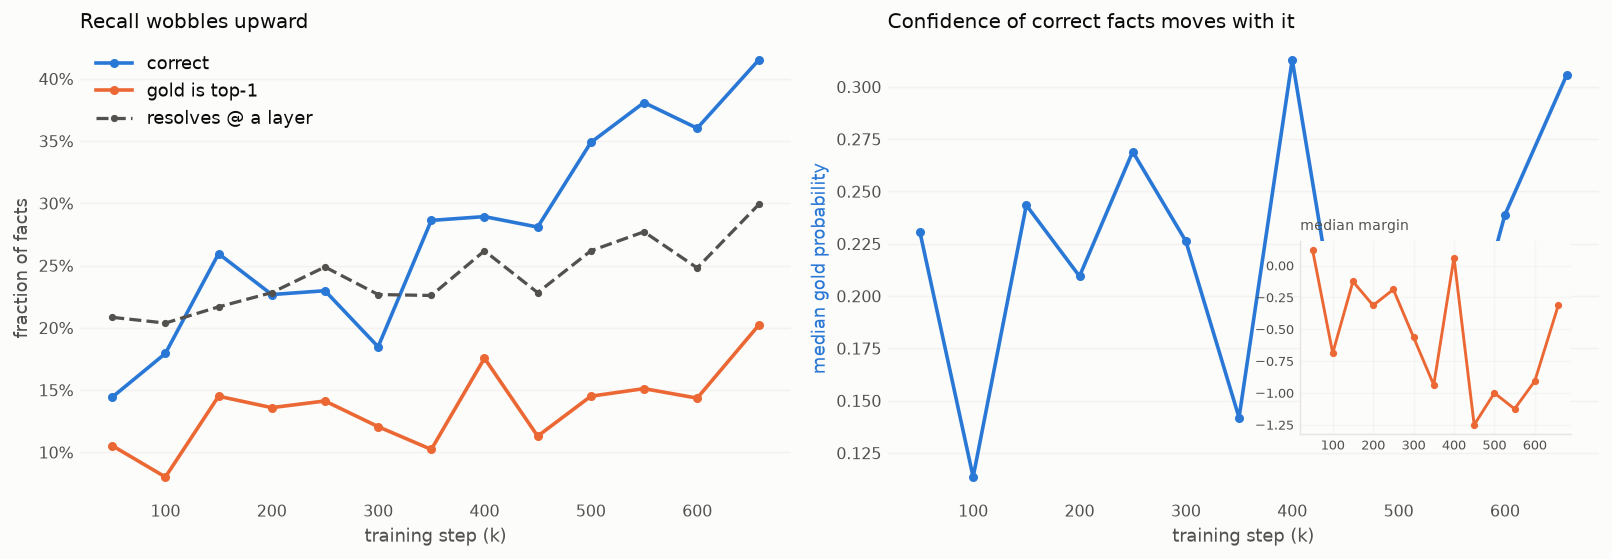

In [2]:
xk = [s / 1000 for s in steps]
frac_correct = correct.mean(axis=0)
frac_top1 = P["is_top1"].to_numpy().mean(axis=0)
frac_resolve = (~np.isnan(P["resolution_depth"].to_numpy())).mean(axis=0)

# confidence among the facts correct at each checkpoint
gp = P["gold_prob"].to_numpy(); am = P["answer_margin"].to_numpy()
med_gp = np.array([np.nanmedian(gp[correct[:, t], t]) for t in range(n_steps)])
med_am = np.array([np.nanmedian(am[correct[:, t], t]) for t in range(n_steps)])

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12.5, 4.4))
ax1.plot(xk, frac_correct, color=BLUE, lw=2, marker="o", ms=4, label="correct")
ax1.plot(xk, frac_top1, color=ORANGE, lw=2, marker="o", ms=4, label="gold is top-1")
ax1.plot(xk, frac_resolve, color=INK2, lw=1.8, marker="o", ms=3, ls="--",
         label="resolves @ a layer")
ax1.yaxis.set_major_formatter(plt.FuncFormatter(pfmt))
ax1.set_ylabel("fraction of facts")
ax1.set_title("Recall wobbles upward", loc="left")
ax1.legend(loc="upper left")

ax2.plot(xk, med_gp, color=BLUE, lw=2, marker="o", ms=4, label="median gold prob.")
ax2b = ax2  # single axis; margin plotted on twin-free secondary via normalization
ax2.set_ylabel("median gold probability", color=BLUE)
ax2.set_title("Confidence of correct facts moves with it", loc="left")
# answer margin shares the story but has a different scale -> its own small panel
axin = ax2.inset_axes([0.58, 0.14, 0.38, 0.42])
axin.plot(xk, med_am, color=ORANGE, lw=1.6, marker="o", ms=3)
axin.set_title("median margin", fontsize=8, color=INK2, loc="left")
axin.tick_params(labelsize=7, length=0)
axin.grid(alpha=0.3)

for ax in (ax1, ax2):
    ax.set_xlabel("training step (k)")
    ax.grid(axis="y", alpha=0.4)
    ax.tick_params(length=0)
    for s in ax.spines.values():
        s.set_visible(False)
fig.tight_layout()

## 2 — Forgetting strikes fragile facts

Take every checkpoint at which a fact is **correct**, and split by what happens
next: does it **survive** to the next checkpoint or get **forgotten**? Comparing
the internal signals *at the current (still-correct) checkpoint* shows the two
groups are already far apart. A fact about to be forgotten is only marginally
correct -- low gold probability, a strongly negative margin, and a gold rank that
is near, but not at, 1.

1003 forget vs 3151 survive events


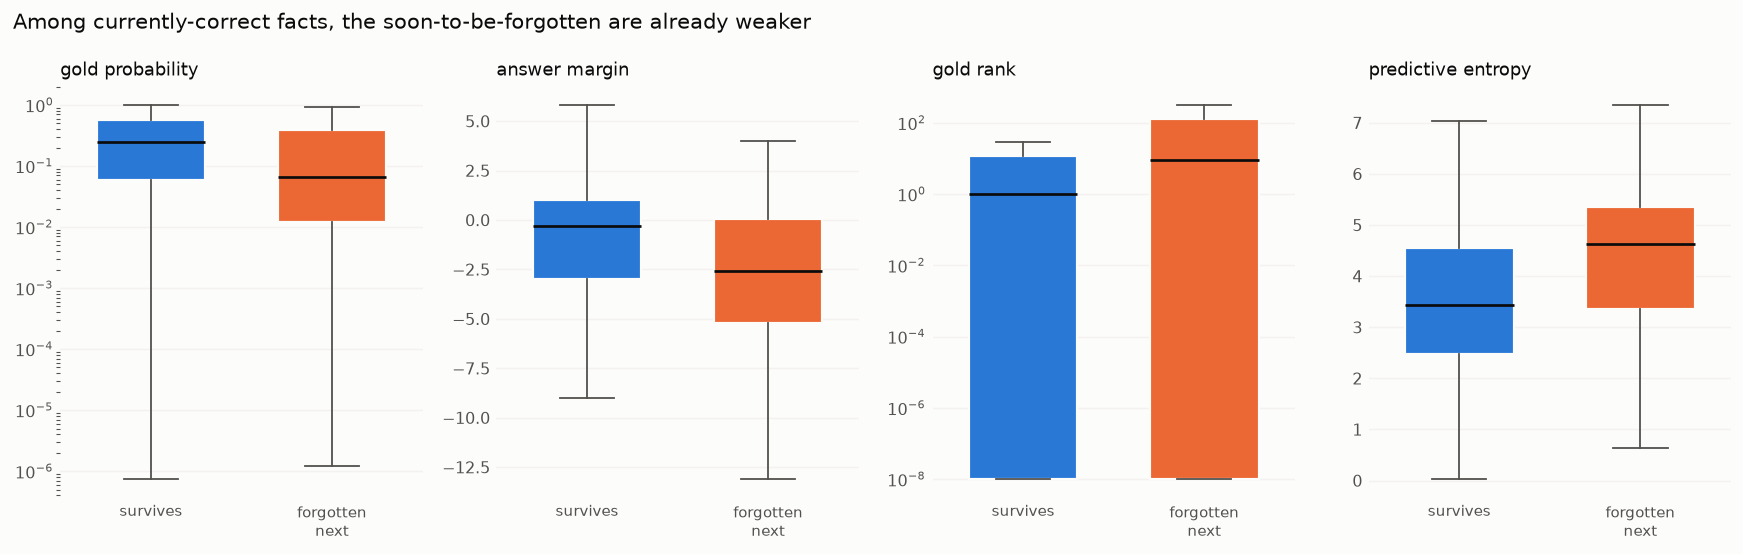

In [3]:
# gather currently-correct observations, labelled by next-step outcome
rows = {k: [] for k in ["gold_prob", "answer_margin", "gold_rank", "pred_entropy"]}
label_forget = []
for t in range(n_steps - 1):
    cur = correct[:, t]
    if not cur.any():
        continue
    for k in rows:
        rows[k].append(P[k].to_numpy()[cur, t])
    label_forget.append(~correct[cur, t + 1])
for k in rows:
    rows[k] = np.concatenate(rows[k])
label_forget = np.concatenate(label_forget)

PANELS = [("gold_prob", "gold probability", True),
          ("answer_margin", "answer margin", False),
          ("gold_rank", "gold rank", True),
          ("pred_entropy", "predictive entropy", False)]
fig, axes = plt.subplots(1, 4, figsize=(13.5, 4.3))
for ax, (k, label, log) in zip(axes, PANELS):
    v = rows[k]
    surv = v[~label_forget]; forg = v[label_forget]
    if log:
        surv = np.clip(surv, 1e-8, None); forg = np.clip(forg, 1e-8, None)
    bp = ax.boxplot([surv, forg], patch_artist=True, widths=0.6, showfliers=False,
                    medianprops=dict(color=INK, lw=1.5),
                    whiskerprops=dict(color=INK2), capprops=dict(color=INK2))
    for patch, col in zip(bp["boxes"], (C_SURV, C_FORG)):
        patch.set_facecolor(col); patch.set_edgecolor(SURF); patch.set_linewidth(1.2)
    if log:
        ax.set_yscale("log")
    ax.set_xticks([1, 2], ["survives", "forgotten\nnext"], fontsize=8.5)
    ax.set_title(label, loc="left", fontsize=10)
    ax.grid(axis="y", alpha=0.4); ax.tick_params(length=0)
    for s in ax.spines.values():
        s.set_visible(False)
fig.suptitle("Among currently-correct facts, the soon-to-be-forgotten are already weaker",
             x=0.01, ha="left", fontsize=11.5)
fig.tight_layout()
print(f"{label_forget.sum()} forget vs {(~label_forget).sum()} survive events")

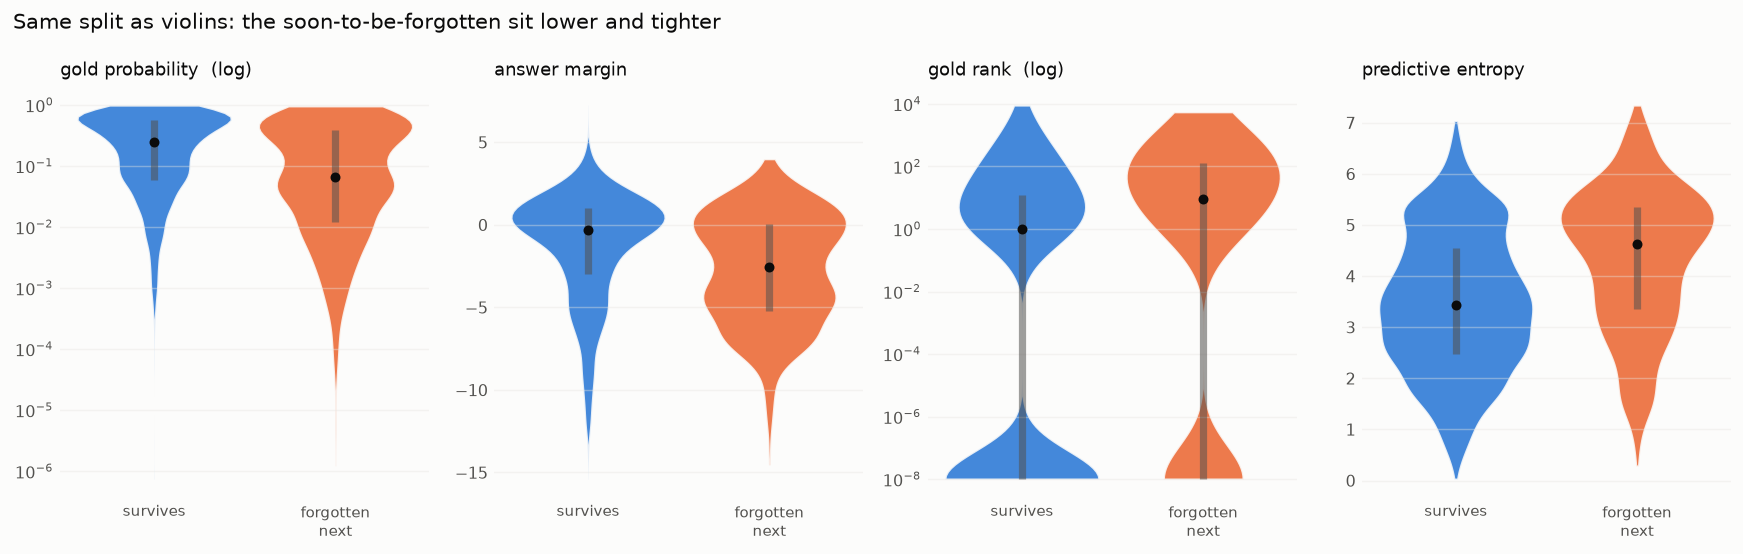

In [4]:
# same comparison as violins (KDE of the full distribution instead of quartile boxes)
from matplotlib.ticker import FuncFormatter

fig, axes = plt.subplots(1, 4, figsize=(13.5, 4.3))
for ax, (k, label, log) in zip(axes, PANELS):
    v = rows[k]
    surv = v[~label_forget]; forg = v[label_forget]
    if log:                                   # KDE in log space -> undistorted shape
        surv = np.log10(np.clip(surv, 1e-8, None))
        forg = np.log10(np.clip(forg, 1e-8, None))
    parts = ax.violinplot([surv, forg], positions=[1, 2], widths=0.85,
                          showextrema=False)
    for body, col in zip(parts["bodies"], (C_SURV, C_FORG)):
        body.set_facecolor(col); body.set_edgecolor(SURF)
        body.set_alpha(0.88); body.set_linewidth(1.2)
    # median dot + IQR bar overlaid, so the summary the boxplot showed stays readable
    for pos, d in zip((1, 2), (surv, forg)):
        q1, med, q3 = np.percentile(d, [25, 50, 75])
        ax.vlines(pos, q1, q3, color=INK2, lw=4, alpha=0.55, zorder=2)
        ax.plot(pos, med, "o", color=INK, ms=4.5, zorder=3)
    if log:
        ax.yaxis.set_major_formatter(
            FuncFormatter(lambda y, _: f"$10^{{{int(round(y))}}}$"))
    ax.set_xticks([1, 2], ["survives", "forgotten\nnext"], fontsize=8.5)
    ax.set_title(label + ("  (log)" if log else ""), loc="left", fontsize=10)
    ax.grid(axis="y", alpha=0.4); ax.tick_params(length=0)
    for s in ax.spines.values():
        s.set_visible(False)
fig.suptitle("Same split as violins: the soon-to-be-forgotten sit lower and tighter",
             x=0.01, ha="left", fontsize=11.5)
fig.tight_layout()

## 3 — No cliff: forgotten facts were fragile all along

Aligning on the forgetting event (τ = 0 is the last correct checkpoint, τ = +1 the
first wrong one) shows the internal confidence of these facts is **flat and low**
across the whole window -- there is no sharp collapse at the flip. They hover near
the decision boundary and tip over. The dashed line is the median for facts that
stay correct: a different regime entirely.

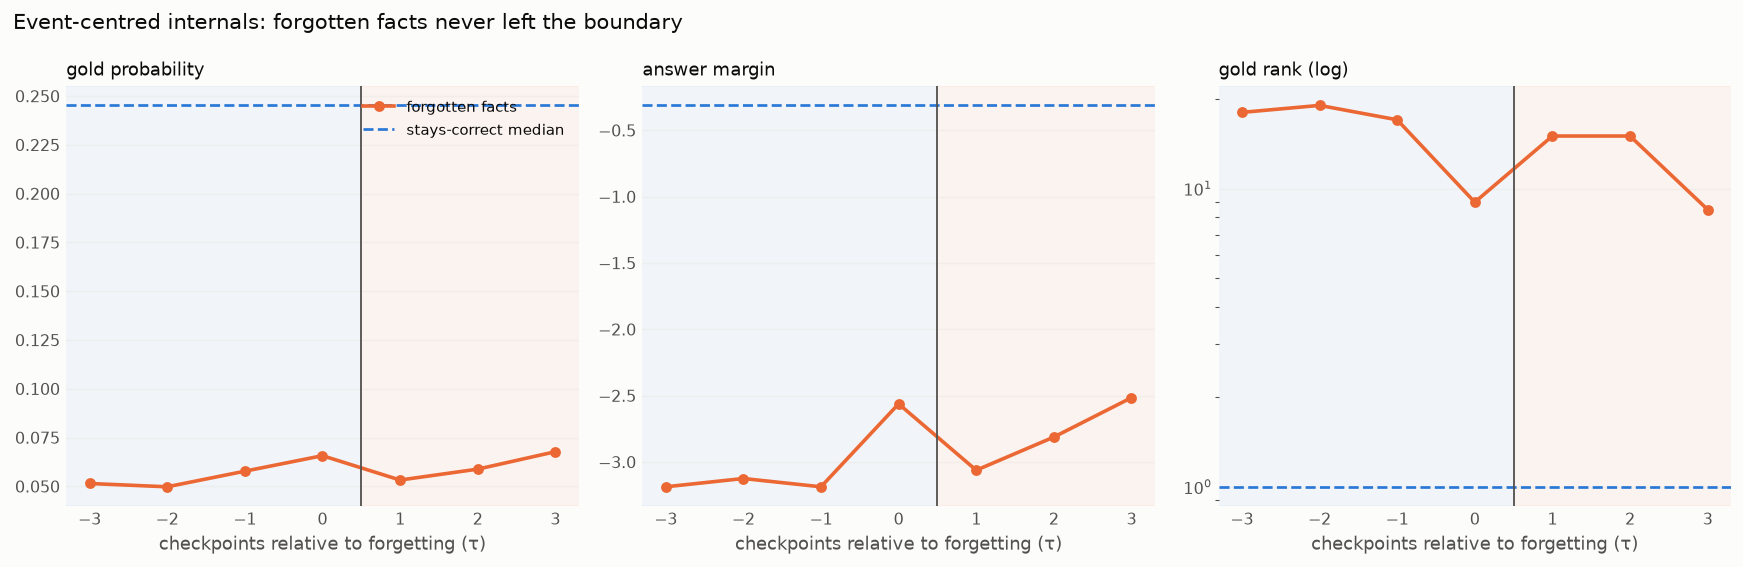

In [5]:
offsets = range(-3, 4)
def event_curve(feat):
    M = P[feat].to_numpy()
    med = {}
    for tau in offsets:
        vals = []
        for t in range(n_steps - 1):
            forget = correct[:, t] & (~correct[:, t + 1])
            j = t + tau
            if 0 <= j < n_steps:
                vals.append(M[forget, j])
        med[tau] = np.nanmedian(np.concatenate(vals)) if vals else np.nan
    return np.array([med[o] for o in offsets])

# survivor reference: median among currently-correct-and-surviving
surv_ref = {k: np.nanmedian(rows[k][~label_forget]) for k in
            ["gold_prob", "answer_margin", "gold_rank"]}

CURVES = [("gold_prob", "gold probability", False),
          ("answer_margin", "answer margin", False),
          ("gold_rank", "gold rank (log)", True)]
xo = list(offsets)
fig, axes = plt.subplots(1, 3, figsize=(13.5, 4.4))
for ax, (k, label, log) in zip(axes, CURVES):
    y = event_curve(k)
    ax.axvspan(-3.5, 0.5, color=BLUE, alpha=0.05)      # labelled correct
    ax.axvspan(0.5, 3.5, color=ORANGE, alpha=0.06)     # labelled wrong
    ax.plot(xo, y, color=C_FORG, lw=2, marker="o", ms=5, label="forgotten facts")
    ax.axhline(surv_ref[k], color=C_SURV, ls="--", lw=1.5, label="stays-correct median")
    ax.axvline(0.5, color=INK2, lw=1)
    if log:
        ax.set_yscale("log")
    ax.set_xlim(-3.3, 3.3)
    ax.set_xlabel("checkpoints relative to forgetting (τ)")
    ax.set_title(label, loc="left", fontsize=10)
    ax.grid(axis="y", alpha=0.4); ax.tick_params(length=0)
    for s in ax.spines.values():
        s.set_visible(False)
axes[0].legend(loc="upper right", fontsize=8.5)
fig.suptitle("Event-centred internals: forgotten facts never left the boundary",
             x=0.01, ha="left", fontsize=11.5)
fig.tight_layout()

## 4 — Retrieval failure or readout failure?

At the flip, is the answer *gone from the model* or just *not emitted*? For the
forgotten facts we compare the last-correct checkpoint (τ = 0) with the first-wrong
one (τ = +1). Both the output signal (`is_top1`) and the internal one (still
resolves at some layer) drop -- but note how **low they already are at τ = 0**:
most of these facts were correct by the lenient substring match without gold ever
being the top token or resolving internally. Forgetting is mostly the tipping of
facts that were **never robustly stored**, not the erasure of solid knowledge.

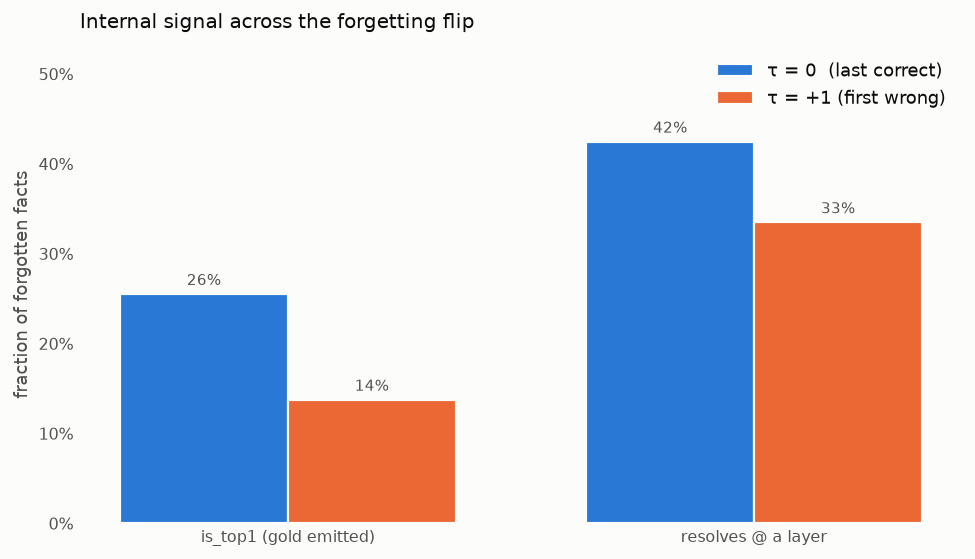

In [6]:
def rate_at(mask_feat, tau, kind):
    vals = []
    M = P[mask_feat].to_numpy()
    for t in range(n_steps - 1):
        forget = correct[:, t] & (~correct[:, t + 1])
        j = t + tau
        if 0 <= j < n_steps:
            col = M[forget, j]
            if kind == "resolve":
                vals.append(~np.isnan(col))
            else:
                vals.append(col.astype(float))
    return np.nanmean(np.concatenate(vals))

metrics = ["is_top1 (gold emitted)", "resolves @ a layer"]
at0 = [rate_at("is_top1", 0, "bool"), rate_at("resolution_depth", 0, "resolve")]
at1 = [rate_at("is_top1", 1, "bool"), rate_at("resolution_depth", 1, "resolve")]

fig, ax = plt.subplots(figsize=(7.6, 4.4))
x = np.arange(len(metrics)); w = 0.36
ax.bar(x - w/2, at0, w, color=BLUE, edgecolor=SURF, linewidth=1.2,
       label="τ = 0  (last correct)")
ax.bar(x + w/2, at1, w, color=ORANGE, edgecolor=SURF, linewidth=1.2,
       label="τ = +1 (first wrong)")
for xi, (a, b) in enumerate(zip(at0, at1)):
    ax.text(xi - w/2, a + 0.01, f"{a:.0%}", ha="center", fontsize=8.5, color=INK2)
    ax.text(xi + w/2, b + 0.01, f"{b:.0%}", ha="center", fontsize=8.5, color=INK2)
ax.set_xticks(x, metrics)
ax.set_ylim(0, max(at0 + at1) * 1.25)
ax.yaxis.set_major_formatter(plt.FuncFormatter(pfmt))
ax.set_ylabel("fraction of forgotten facts")
ax.set_title("Internal signal across the forgetting flip", loc="left", pad=10)
ax.legend(loc="upper right"); ax.tick_params(length=0)
for s in ax.spines.values():
    s.set_visible(False)
fig.tight_layout()

## 5 — Internal confidence predicts forgetting a checkpoint ahead

Putting it together: bin every currently-correct observation by its gold
probability and measure how often it is forgotten at the next checkpoint. The
relationship is monotonic -- the weakest decile is forgotten ~3x as often as the
strongest. A single scalar (gold probability, or the answer margin) gives a real,
if modest, one-step-ahead warning (AUC ≈ 0.64); being top-1 roughly halves the
risk.

AUC  gold_prob -> forget      : 0.638
AUC  answer_margin -> forget  : 0.632
P(forget | gold is top-1)     : 18.9%
P(forget | gold not top-1)    : 32.6%


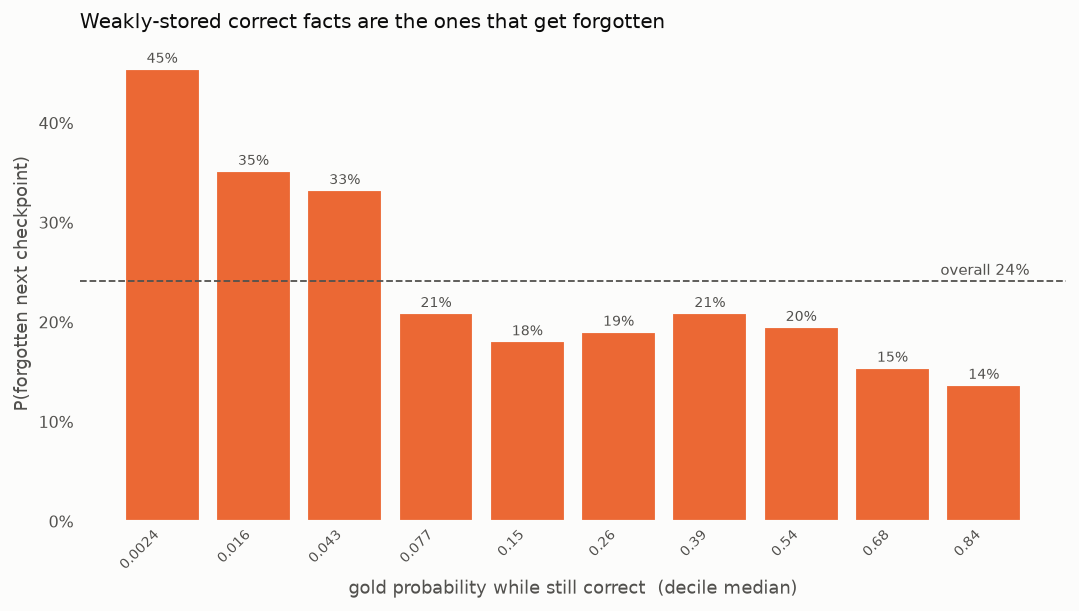

In [7]:
from scipy.stats import rankdata
def auc(score, y):                       # P(score ranks a positive above a negative)
    m = ~np.isnan(score)
    score, y = score[m], y[m].astype(bool)
    r = rankdata(score)
    n1 = y.sum(); n0 = (~y).sum()
    return (r[y].sum() - n1 * (n1 + 1) / 2) / (n1 * n0)

gpv = rows["gold_prob"]; amv = rows["answer_margin"]
auc_gp = auc(-gpv, label_forget)          # lower prob -> more likely forgotten
auc_am = auc(-amv, label_forget)

m = ~np.isnan(gpv)
dec = pd.qcut(gpv[m], 10, labels=False, duplicates="drop")
lab = label_forget[m]
gpm = gpv[m]
p_forget = np.array([lab[dec == d].mean() for d in range(dec.max() + 1)])
gp_med = np.array([np.median(gpm[dec == d]) for d in range(dec.max() + 1)])

fig, ax = plt.subplots(figsize=(8.4, 4.8))
xb = np.arange(len(p_forget))
ax.bar(xb, p_forget, color=ORANGE, edgecolor=SURF, linewidth=1.2, width=0.82)
for i, v in enumerate(p_forget):
    ax.text(i, v + 0.006, f"{v:.0%}", ha="center", fontsize=8, color=INK2)
ax.axhline(label_forget.mean(), color=INK2, ls="--", lw=1)
ax.text(len(p_forget) - 0.5, label_forget.mean() + 0.006,
        f"overall {label_forget.mean():.0%}", ha="right", fontsize=8.5, color=INK2)
ax.set_xticks(xb, [f"{v:.2g}" for v in gp_med], rotation=45, ha="right", fontsize=8)
ax.set_xlabel("gold probability while still correct  (decile median)")
ax.yaxis.set_major_formatter(plt.FuncFormatter(pfmt))
ax.set_ylabel("P(forgotten next checkpoint)")
ax.set_title("Weakly-stored correct facts are the ones that get forgotten",
             loc="left", pad=10)
ax.tick_params(length=0)
for s in ax.spines.values():
    s.set_visible(False)
fig.tight_layout()

print(f"AUC  gold_prob -> forget      : {auc_gp:.3f}")
print(f"AUC  answer_margin -> forget  : {auc_am:.3f}")
print(f"P(forget | gold is top-1)     : {label_forget[rows['gold_rank']==1].mean():.1%}")
print(f"P(forget | gold not top-1)    : {label_forget[rows['gold_rank']>1].mean():.1%}")

## 6 — Forgetting by relation type

Does the fragility story play out differently across relations? We measure a
per-relation **forgetting hazard** -- the probability that a fact correct at one
checkpoint is wrong at the next, pooled over all checkpoints -- and connect it to
the same internal signal used above.

- **6a** ranks relations by hazard. Some are stable (`capital`, `capital of` ~17%),
  others churn constantly (`genre`, `country` > 60%). Relations with few correct
  observations are greyed out -- their hazard is noisy.
- **6b** shows *when* each relation wobbles: a checkpoint-by-checkpoint accuracy
  heatmap. Stable relations stay dark across training; volatile ones flicker.
- **6c** ties it back to the mechanism: relations whose correct facts are stored
  with low gold probability (fragile) have the highest hazard -- the same
  weak-storage → forgetting link as at the per-fact level, now across relations.

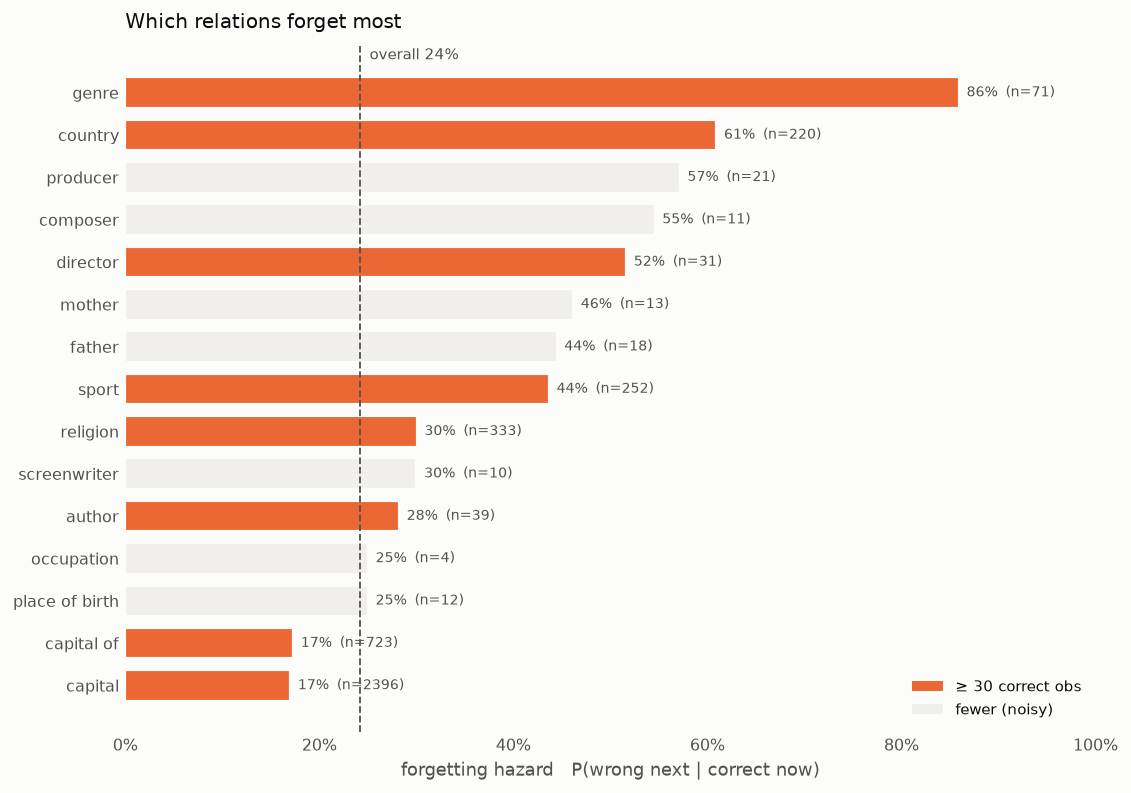

In [8]:
# 6a — forgetting hazard by relation type
# hazard = P(wrong next checkpoint | correct now), pooled over all checkpoints.
MIN_OBS = 30                       # a relation needs this many correct (fact,ckpt) obs to be reliable
gp_all = P["gold_prob"].to_numpy()
recs = []
for p in np.unique(prop):
    m = prop == p
    cur = correct[m, :-1]; nxt = correct[m, 1:]
    n_obs = int(cur.sum())                                   # correct (fact, ckpt) observations
    gpc = gp_all[m, :][correct[m, :]]
    recs.append(dict(prop=p, n_facts=int(m.sum()), n_obs=n_obs,
                     hazard=(cur & ~nxt).sum() / n_obs if n_obs else np.nan,
                     gp_correct=np.nanmedian(gpc) if len(gpc) else np.nan,
                     exposure=np.median(exposure[m])))
prop_stats = pd.DataFrame(recs).sort_values("hazard").reset_index(drop=True)
overall_hz = (correct[:, :-1] & ~correct[:, 1:]).sum() / correct[:, :-1].sum()

fig, ax = plt.subplots(figsize=(8.8, 6.2))
yp = np.arange(len(prop_stats))
reliable = prop_stats["n_obs"] >= MIN_OBS
ax.barh(yp, prop_stats["hazard"],
        color=[ORANGE if r else NEUTRAL for r in reliable],
        edgecolor=SURF, linewidth=1.2, height=0.72)
for i, row in prop_stats.iterrows():
    ax.text(row["hazard"] + 0.008, i, f"{row['hazard']:.0%}  (n={row['n_obs']})",
            va="center", fontsize=8, color=INK2)
ax.axvline(overall_hz, color=INK2, ls="--", lw=1)
ax.text(overall_hz, len(prop_stats) - 0.3, f"  overall {overall_hz:.0%}",
        color=INK2, fontsize=8.5, va="bottom")
ax.set_yticks(yp, prop_stats["prop"], fontsize=9)
ax.set_xlim(0, 1)
ax.xaxis.set_major_formatter(plt.FuncFormatter(pfmt))
ax.set_xlabel("forgetting hazard   P(wrong next | correct now)")
ax.set_title("Which relations forget most", loc="left", pad=10)
ax.tick_params(length=0)
for s in ax.spines.values():
    s.set_visible(False)
from matplotlib.patches import Patch
ax.legend(handles=[Patch(facecolor=ORANGE, label=f"≥ {MIN_OBS} correct obs"),
                   Patch(facecolor=NEUTRAL, label="fewer (noisy)")],
          loc="lower right", fontsize=8.5)
fig.tight_layout()

Most stable: capital (17%), capital of (17%), author (28%).
Most volatile: genre (86%), country (61%), producer (57%).
Relations with fewer than 30 correct observations (occupation, screenwriter, composer, mother, …) are greyed out and labeled with their n, since their hazard is noisy.

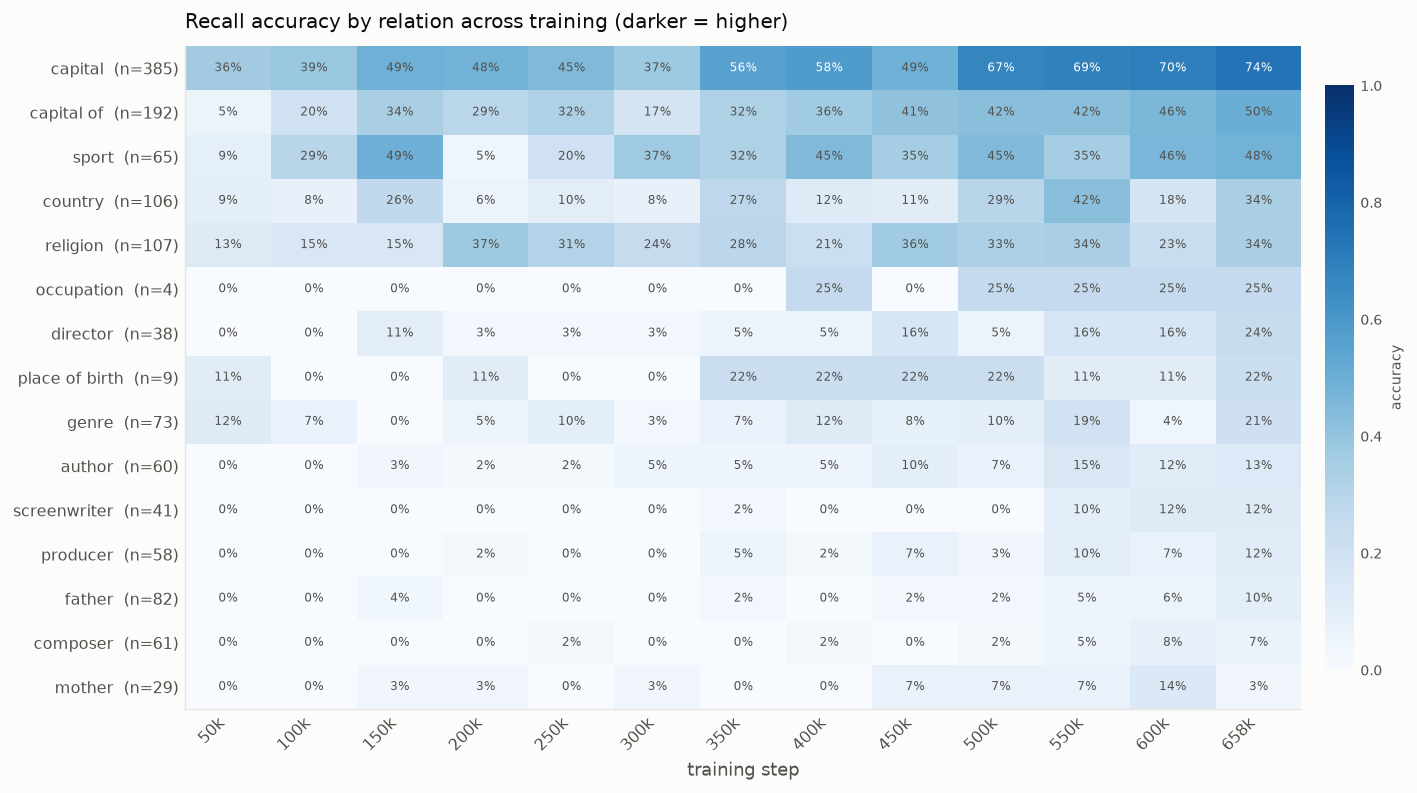

In [9]:
# 6b — when each relation wobbles: accuracy heatmap across training
props_u = np.unique(prop)
acc = np.array([[correct[prop == p, t].mean() for t in range(n_steps)]
                for p in props_u])
row_order = np.argsort(-acc[:, -1])            # most-recalled relations on top
acc = acc[row_order]; props_u = props_u[row_order]

fig, ax = plt.subplots(figsize=(11, 6.2))
im = ax.imshow(acc, aspect="auto", cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(n_steps), [f"{s//1000}k" for s in steps], rotation=45, ha="right")
ax.set_yticks(range(len(props_u)),
              [f"{p}  (n={(prop==p).sum()})" for p in props_u], fontsize=9)
for i in range(acc.shape[0]):
    for j in range(acc.shape[1]):
        v = acc[i, j]
        ax.text(j, i, f"{v:.0%}", ha="center", va="center", fontsize=6.5,
                color="white" if v > 0.55 else INK2)
ax.set_xlabel("training step")
ax.set_title("Recall accuracy by relation across training (darker = higher)",
             loc="left", pad=10)
ax.tick_params(length=0)
cb = fig.colorbar(im, ax=ax, fraction=0.025, pad=0.02)
cb.set_label("accuracy", fontsize=8); cb.outline.set_visible(False)
cb.ax.tick_params(length=0, labelsize=8)
fig.tight_layout()

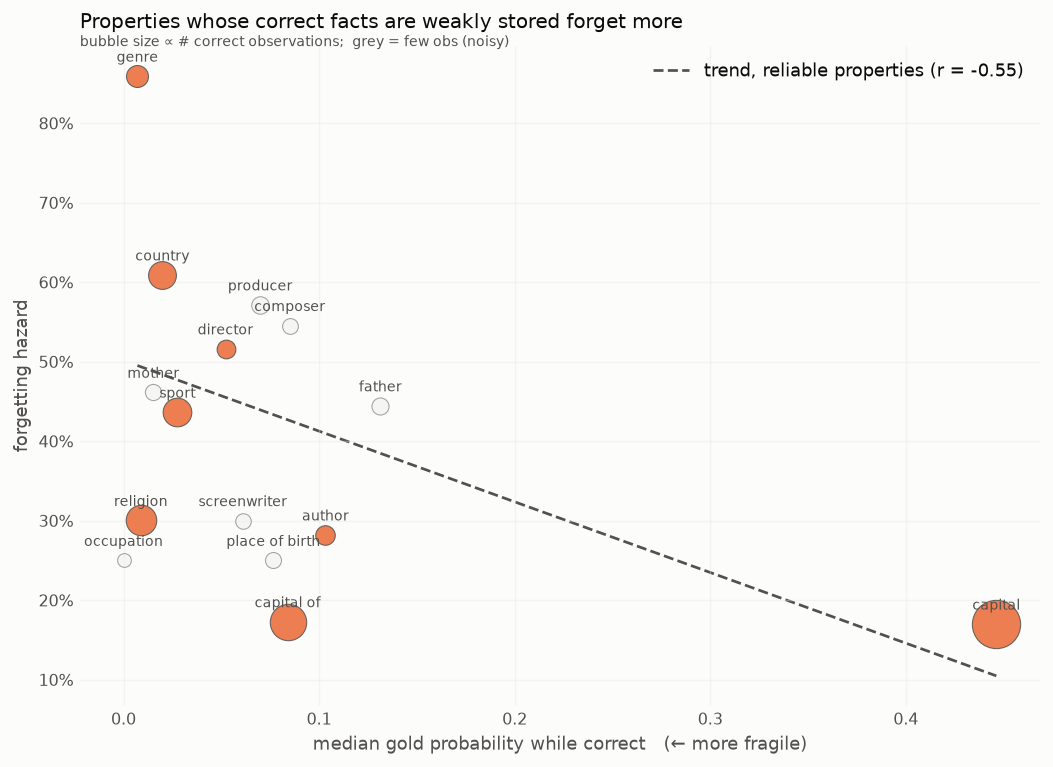

In [10]:
# 6c — the fragility mechanism holds across relations
rel = prop_stats[prop_stats["n_obs"] >= MIN_OBS]      # fit only where hazard is reliable
b, a = np.polyfit(rel["gp_correct"], rel["hazard"], 1)
r = np.corrcoef(rel["gp_correct"], rel["hazard"])[0, 1]
xs = np.linspace(rel["gp_correct"].min(), rel["gp_correct"].max(), 40)

fig, ax = plt.subplots(figsize=(8.2, 6))
ax.plot(xs, a + b * xs, color=INK2, ls="--", lw=1.5, zorder=1,
        label=f"trend, reliable properties (r = {r:.2f})")
for _, row in prop_stats.iterrows():
    reli = row["n_obs"] >= MIN_OBS
    ax.scatter(row["gp_correct"], row["hazard"],
               s=np.sqrt(row["n_obs"]) * 14 + 30,
               color=ORANGE if reli else NEUTRAL, alpha=0.85 if reli else 0.5,
               edgecolor=INK2, linewidth=0.6, zorder=2)
    ax.annotate(row["prop"], (row["gp_correct"], row["hazard"]), fontsize=7.5,
                color=INK2, xytext=(0, 8), textcoords="offset points", ha="center")
ax.yaxis.set_major_formatter(plt.FuncFormatter(pfmt))
ax.set_xlabel("median gold probability while correct   (← more fragile)")
ax.set_ylabel("forgetting hazard")
ax.set_title("Properties whose correct facts are weakly stored forget more",
             loc="left", pad=10)
ax.grid(alpha=0.35)
ax.legend(loc="upper right")
ax.text(0.0, 1, "bubble size ∝ # correct observations;  grey = few obs (noisy)",
        transform=ax.transAxes, fontsize=8, color=INK2)
ax.tick_params(length=0)
for s in ax.spines.values():
    s.set_visible(False)
fig.tight_layout()

---
# ═══════════════════════ NEW WORK STARTS HERE ═══════════════════════

# Part II — literature grounding and follow-up tests

Everything above this line is the original analysis. Everything below is new:
a short literature review, then a set of **follow-up tests**, each one labelled
with the paper it leans on. Section numbering continues from §6.

## A short literature overview

**Forgetting as a measurable training-dynamics event.** The correct→wrong
transition used throughout this notebook is the *forgetting event* of
**Toneva et al. (2019)**, *An Empirical Study of Example Forgetting during Deep
Neural Network Learning* (ICLR) — they count, per example, how often it flips from
correct to incorrect over training, and find a large population of *unforgettable*
examples that are never lost. **Maini et al. (2022)**, *Characterizing Datapoints
via Second-Split Forgetting* (NeurIPS), use the *time* of forgetting to separate
genuinely hard/rare examples from mislabelled ones. **Swayamdipta et al. (2020)**,
*Dataset Cartography* (EMNLP), map examples by the **mean** and **standard
deviation** of the gold probability across training and read off easy / hard /
ambiguous regions. §7 below is that map, drawn for facts instead of examples.

**Forgetting during LM pretraining specifically.** **Tirumala et al. (2022)**,
*Memorization Without Overfitting* (NeurIPS), track memorisation and forgetting
curves across pretraining and find forgetting baselines that scale with model size.
**Jagielski et al. (2023)**, *Measuring Forgetting of Memorized Training Examples*
(ICLR), show that examples seen early are progressively forgotten. Closest to this
project, **Chang et al. (2024)**, *How Do Large Language Models Acquire Factual
Knowledge During Pretraining?* (NeurIPS), inject facts into pretraining and fit
**decay curves** to the subsequent forgetting, finding acquisition happens in
sharp jumps followed by power-law-ish decay, modulated by batch size and duplication.
**Zucchet et al. (2025)**, *How Do Language Models Learn Facts?*, describe a
three-phase dynamic (plateau → rapid acquisition → degradation). The LMEnt
learning–forgetting wobble analysed here is the same phenomenon with the training
corpus fully known.

**What forgetting looks like inside the network.** **Ramasesh et al. (2021)**,
*Anatomy of Catastrophic Forgetting: Hidden Representations and Task Semantics*
(ICLR), is the reference point for asking the question representationally: they
find forgetting is concentrated in *later* layers and is strongly modulated by
semantic similarity between what is learned and what is lost. **Davari et al.
(2022)**, *Probing Representation Forgetting* (CVPR), draw the crucial distinction
this notebook's §4 gropes toward: **observed forgetting** (the read-out fails) is
much larger than **representation forgetting** (a linear probe on frozen features
still recovers the answer). **Kotha et al. (2024)**, *Understanding Catastrophic
Forgetting in Language Models via Implicit Inference* (ICLR), argue much apparent
forgetting is not erasure at all but a shift in which implicit task the model
infers — a competing answer takes over. §9 tests exactly that fork.

**Where factual recall lives.** **Geva et al. (2021, 2022)** established FFN layers
as key–value memories that promote concepts in vocabulary space; **Meng et al.
(2022)** (ROME) localised factual associations to mid-stack MLPs at the **last
subject token** via causal tracing; **Geva et al. (2023)**, *Dissecting Recall of
Factual Associations*, split recall into **subject enrichment** at the subject
position and **attribute extraction** to the last position. That two-stage picture
is why the extraction stored both an `answer` and a `subject_last` position, and it
predicts *where in the stack* forgetting should first become visible — §8.

**Reading the stack.** The `resolution_depth` / `gold_rank_by_layer` features are
the **logit lens** (**nostalgebraist, 2020**), refined by **Belrose et al. (2023)**,
*Eliciting Latent Predictions with the Tuned Lens*, whose main warning is that the
raw logit lens is biased at early layers and at the final layer. **Lad et al.
(2024)**, *The Remarkable Robustness of LLMs: Stages of Inference*, give the
now-standard four-stage reading of depth that §8 interprets against.

**Active neurons.** **Dai et al. (2022)**, *Knowledge Neurons in Pretrained
Transformers* (ACL), and **Gurnee et al. (2023)**, *Finding Neurons in a Haystack*,
localise facts to small neuron sets; **Voita et al. (2024)**, *Neurons in Large
Language Models: Dead, N-gram, Positional* (ACL Findings), document how activation
sparsity varies with depth and training. **Kim et al. (2025)**, *Knowledge Entropy
Decay during Language Model Pretraining Hinders New Knowledge Acquisition* (ICLR),
is the most directly relevant: they measure how *broadly* the FFN memories are
engaged and show that this breadth **decays** over pretraining, and that low
breadth predicts more forgetting. The `mlp_participation_by_layer` column is a
close proxy — tested in the companion notebook.

**Why some facts are fragile in the first place.** **Mallen et al. (2023)**,
*When Not to Trust Language Models* (ACL), show factual recall is governed by
subject **popularity**; **Elhage et al. (2022)**, *Toy Models of Superposition*,
predict that features packed into a shared space **interfere**, which is the
mechanism behind a fragility that is about crowding rather than weakness.

## What the new tests are

| § | Test | Leans on |
|---|------|----------|
| 7 | Fact cartography: confidence × variability × forgetting count | Swayamdipta et al. 2020; Toneva et al. 2019 |
| 8 | Logit-lens depth profile of survive vs. forget-next | nostalgebraist 2020; Belrose et al. 2023; Lad et al. 2024; Geva et al. 2023 |
| 9 | Is the flip **decay** or **takeover** by a competitor? | Kotha et al. 2024; Chang et al. 2024 |
| 10 | Noise-floor null: is "forgetting" just a stochastic read-out? | Toneva et al. 2019; Maini et al. 2022 |


In [11]:
# --- shared loader for the new sections: columns the original §1 panel did not keep ---
# (§1 built `P` from FEATURES only; §§7-10 also need top1_prob, gold_rank_by_layer, ...)
EXTRA = ["top1_prob", "pred_entropy", "gold_prob", "generation"]
_frames = []
for f, s in zip(files, steps):
    d = pd.read_parquet(f)
    d = d[~d["excluded"]].set_index("id").reindex(ids)
    _frames.append(d)
NEWP = {c: np.column_stack([fr[c].to_numpy() for fr in _frames]) for c in EXTRA}
# per-layer logit-lens ranks: (n_facts, n_steps, n_layer_boundaries)
GRL = np.stack([np.stack(fr["gold_rank_by_layer"].to_numpy()).astype(float)
                for fr in _frames], axis=1)
n_layers = GRL.shape[2]
print(f"loaded extra columns for {len(ids)} scoreable facts x {n_steps} checkpoints")
print(f"gold_rank_by_layer -> {GRL.shape}  ({n_layers} layer boundaries)")

PURPLE = "#7b5ea7"      # third categorical hue; BLUE/ORANGE/PURPLE pass the CVD checks
                        # (RED is deliberately never paired with ORANGE: OKLab dE 3.6 under
                        #  deuteranopia -- indistinguishable)


loaded extra columns for 1310 scoreable facts x 13 checkpoints
gold_rank_by_layer -> (1310, 13, 19)  (19 layer boundaries)


## 7 — Fact cartography: where do forgotten facts live?

**Paper:** Swayamdipta et al. (2020), *Dataset Cartography: Mapping and Diagnosing
Datasets with Training Dynamics* (EMNLP); Toneva et al. (2019) for the event count.

Cartography plots every example by its **confidence** (mean gold probability across
checkpoints) and **variability** (its standard deviation), and finds three regions:
*easy* (high confidence, low variability), *hard* (low, low) and **ambiguous**
(middling confidence, **high** variability) — the region the paper associates with
unstable learning.

The natural prediction is that forgetting concentrates in the ambiguous,
high-variability region. Testing it here needs one correction the original paper
does not need: for a bounded probability, the standard deviation is mechanically
capped by the mean (a fact averaging 0.02 *cannot* have σ = 0.3), so raw
variability is confounded with confidence. We therefore report both raw
variability and the scale-free **coefficient of variation** (σ/μ).

never forgotten  n= 140  confidence=0.1875  σ=0.1075  σ/μ=0.537
1 event          n= 324  confidence=0.1149  σ=0.0675  σ/μ=0.535
≥2 events        n= 279  confidence=0.0567  σ=0.0294  σ/μ=0.620
corr(σ,   #forget | ever-correct) = -0.090
corr(σ/μ, #forget | ever-correct) = +0.101


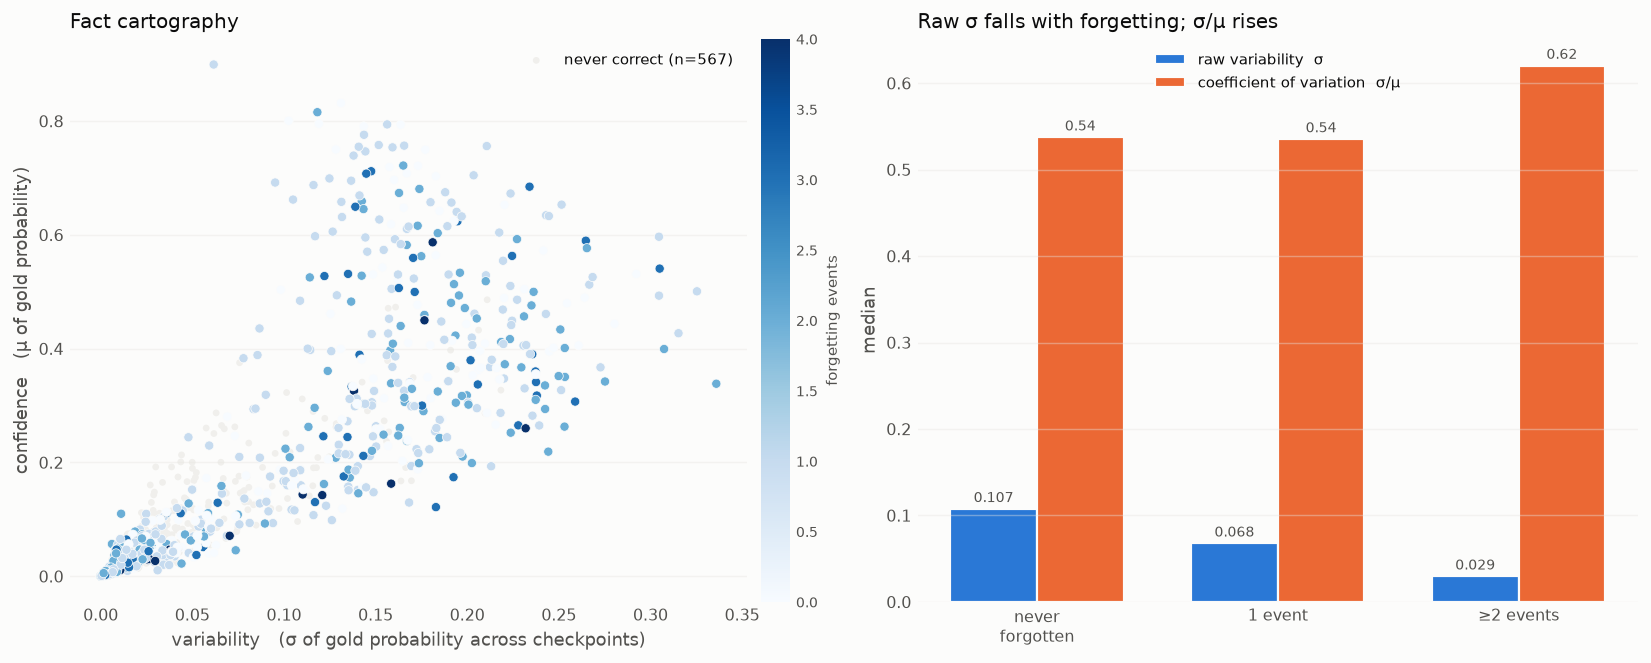

In [12]:
# §7 — cartography of facts  (Swayamdipta et al. 2020; Toneva et al. 2019)
gp_mat = NEWP["gold_prob"]
confidence  = np.nanmean(gp_mat, axis=1)
variability = np.nanstd(gp_mat, axis=1)
coef_var    = variability / np.clip(confidence, 1e-9, None)
n_forget    = (correct[:, :-1] & ~correct[:, 1:]).sum(axis=1)
ever_correct = correct.any(axis=1)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12.8, 5.2))

# --- left: the classic map, colour = number of forgetting events (sequential, one hue)
never = ~ever_correct
ax1.scatter(variability[never], confidence[never], s=14, color=NEUTRAL,
            edgecolor="none", label=f"never correct (n={never.sum()})", zorder=1)
sc_ = ax1.scatter(variability[ever_correct], confidence[ever_correct],
                  c=n_forget[ever_correct], cmap="Blues", s=26,
                  vmin=0, vmax=np.percentile(n_forget[ever_correct], 98),
                  edgecolor=SURF, linewidth=0.4, zorder=2)
cb = fig.colorbar(sc_, ax=ax1, fraction=0.04, pad=0.02)
cb.set_label("forgetting events", fontsize=8.5); cb.outline.set_visible(False)
cb.ax.tick_params(length=0, labelsize=8)
ax1.set_xlabel("variability   (σ of gold probability across checkpoints)")
ax1.set_ylabel("confidence   (μ of gold probability)")
ax1.set_title("Fact cartography", loc="left")
ax1.legend(loc="upper right", fontsize=8.5)

# --- right: group medians, raw σ vs the scale-free σ/μ
groups = [("never\nforgotten", ever_correct & (n_forget == 0)),
          ("1 event",          ever_correct & (n_forget == 1)),
          ("≥2 events",        ever_correct & (n_forget >= 2))]
xg = np.arange(len(groups)); w = 0.36
ax2.bar(xg - w/2, [np.nanmedian(variability[m]) for _, m in groups], w,
        color=BLUE, edgecolor=SURF, linewidth=1.2, label="raw variability  σ")
ax2.bar(xg + w/2, [np.nanmedian(coef_var[m]) for _, m in groups], w,
        color=ORANGE, edgecolor=SURF, linewidth=1.2, label="coefficient of variation  σ/μ")
for i, (_, m) in enumerate(groups):
    ax2.text(i - w/2, np.nanmedian(variability[m]) + .008,
             f"{np.nanmedian(variability[m]):.3f}", ha="center", fontsize=8, color=INK2)
    ax2.text(i + w/2, np.nanmedian(coef_var[m]) + .008,
             f"{np.nanmedian(coef_var[m]):.2f}", ha="center", fontsize=8, color=INK2)
ax2.set_xticks(xg, [g for g, _ in groups])
ax2.set_ylabel("median")
ax2.set_title("Raw σ falls with forgetting; σ/μ rises", loc="left")
ax2.legend(loc="upper center", fontsize=8.5)

for ax in (ax1, ax2):
    ax.grid(axis="y", alpha=.4); ax.tick_params(length=0)
    for s_ in ax.spines.values(): s_.set_visible(False)
fig.tight_layout()

for name, m in groups:
    print(f"{name.replace(chr(10),' '):16s} n={m.sum():4d}  "
          f"confidence={np.nanmedian(confidence[m]):.4f}  "
          f"σ={np.nanmedian(variability[m]):.4f}  σ/μ={np.nanmedian(coef_var[m]):.3f}")
print(f"corr(σ,   #forget | ever-correct) = {np.corrcoef(variability[ever_correct], n_forget[ever_correct])[0,1]:+.3f}")
print(f"corr(σ/μ, #forget | ever-correct) = {np.corrcoef(coef_var[ever_correct], n_forget[ever_correct])[0,1]:+.3f}")


**Result — the cartography prediction does *not* transfer as stated.** Repeatedly
forgotten facts sit at *low* confidence and *low* raw variability (σ = 0.029 for
≥2 events vs 0.108 for never-forgotten); raw σ correlates **negatively** with the
forgetting count (r = −0.09). The ambiguous "high-variability" region of
Swayamdipta et al. is populated by the facts that are *never* forgotten, because
only a fact with substantial probability mass has room to vary.

Once the mean is divided out the original intuition returns, weakly: σ/μ rises
monotonically across the groups (0.54 → 0.54 → 0.62, r = +0.10). So the honest
statement is that **forgetting-prone facts are the low-confidence ones, and only
mildly the erratic ones** — fragility here is proximity to the threshold, not
instability. This is a genuine difference from the supervised-classification
setting cartography was built for, where confidence is not bounded near zero for
most of the map.

## 8 — Where in the stack does a soon-to-be-forgotten fact fail?

**Papers:** nostalgebraist (2020), *interpreting GPT: the logit lens*; Belrose et
al. (2023), *Eliciting Latent Predictions with the Tuned Lens*; Lad et al. (2024),
*The Remarkable Robustness of LLMs: Stages of Inference*; Geva et al. (2023),
*Dissecting Recall of Factual Associations in Auto-Regressive Language Models*.

§3 showed that the *scalar* internals are flat across the forgetting event. But a
scalar is a summary of the final layer only. `gold_rank_by_layer` gives the rank of
the gold token under the logit lens at **every** layer boundary, for every fact and
checkpoint — an unused column so far.

Geva et al. (2023) predict a specific answer: factual recall is *built* mid-stack
(subject enrichment, then attribute extraction), so if forgetting is a failure of
that machinery, survivors and soon-to-be-forgotten facts should be
**indistinguishable early** and diverge exactly where the attribute is extracted.
If instead forgetting were a late read-out/calibration failure, the two groups
would track each other until the very top.

*Caveat, per Belrose et al.:* the raw logit lens is unreliable at the extreme
layers — the layer-18 uptick below is the known final-layer artefact and should not
be over-read.

4154 transitions, forget rate 24.1%
layer :     0     1     2     3     4     5     6     7     8     9    10    11    12    13    14    15    16    17    18
gap   : -0.22 -0.09 -0.10 -0.12 -0.17 -0.07 -0.06  0.02  0.19  0.40  0.82  0.88  1.11  0.95  0.78  0.78  0.78  0.85  0.55


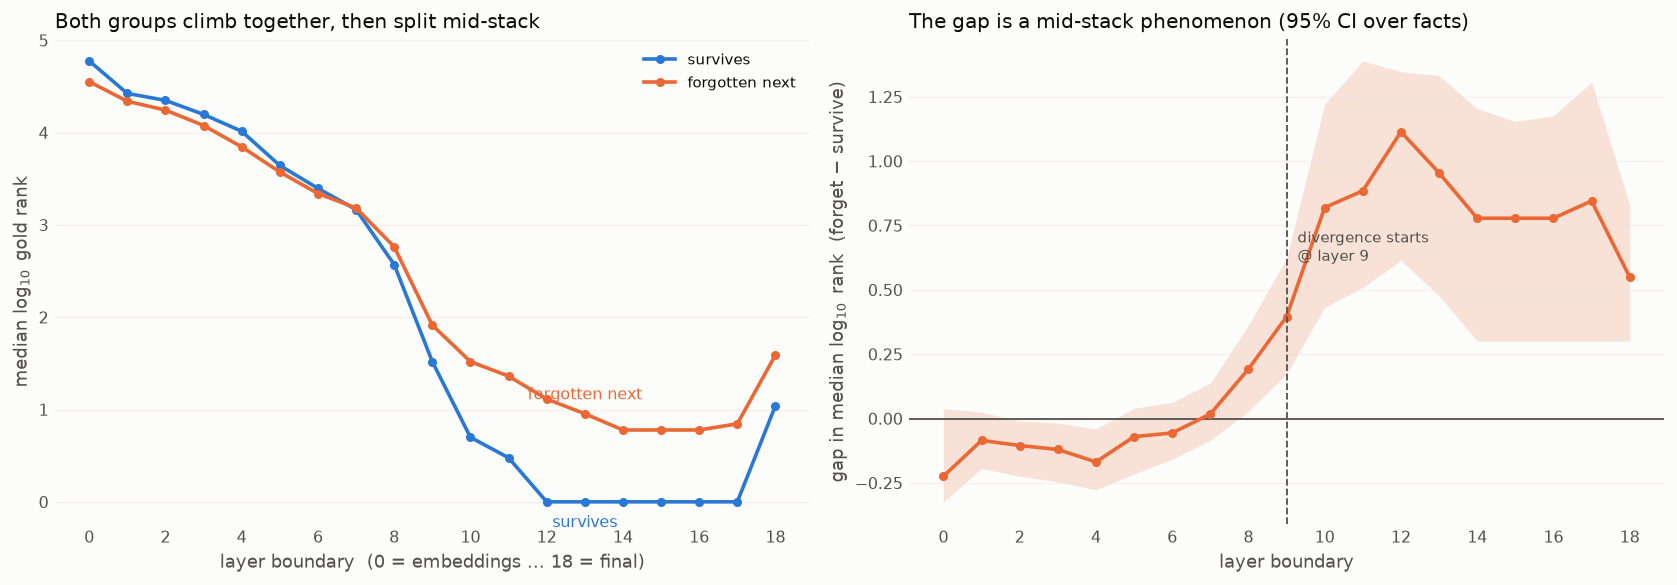

In [13]:
# §8 — logit-lens depth profile, survive vs forget-next
#      (nostalgebraist 2020; Belrose et al. 2023; Lad et al. 2024; Geva et al. 2023)
log_rank = np.log10(np.clip(GRL, 1, None))           # (n_facts, n_steps, n_layers)

tf, tt, tfg = [], [], []
for t in range(n_steps - 1):
    idx = np.where(correct[:, t])[0]
    tf.append(idx); tt.append(np.full(idx.size, t)); tfg.append(~correct[idx, t + 1])
TF, TT, TFG = np.concatenate(tf), np.concatenate(tt), np.concatenate(tfg).astype(bool)
cur = log_rank[TF, TT]                                # (n_transitions, n_layers)
med_s, med_f = np.median(cur[~TFG], 0), np.median(cur[TFG], 0)

# bootstrap the gap over facts (the unit of resampling is the fact, not the transition)
rng = np.random.default_rng(0)
uf = np.unique(TF); boot = []
for _ in range(300):
    pick = rng.choice(uf, uf.size, replace=True)
    sel = np.concatenate([np.where(TF == f)[0] for f in pick[:250]])
    boot.append(np.median(cur[sel][TFG[sel]], 0) - np.median(cur[sel][~TFG[sel]], 0))
boot = np.array(boot); lo_b, hi_b = np.percentile(boot, [2.5, 97.5], axis=0)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.6))
xl = np.arange(n_layers)
ax1.plot(xl, med_s, color=BLUE, lw=2, marker="o", ms=4, label="survives")
ax1.plot(xl, med_f, color=ORANGE, lw=2, marker="o", ms=4, label="forgotten next")
ax1.annotate("survives", (xl[13], med_s[13]), color=BLUE, fontsize=9,
             xytext=(0, -14), textcoords="offset points", ha="center")
ax1.annotate("forgotten next", (xl[13], med_f[13]), color=ORANGE, fontsize=9,
             xytext=(0, 8), textcoords="offset points", ha="center")
ax1.set_xlabel("layer boundary  (0 = embeddings … 18 = final)")
ax1.set_ylabel("median $\\log_{10}$ gold rank")
ax1.set_title("Both groups climb together, then split mid-stack", loc="left")
ax1.legend(loc="upper right", fontsize=8.5)

ax2.axhline(0, color=INK2, lw=1)
ax2.fill_between(xl, lo_b, hi_b, color=ORANGE, alpha=.18, linewidth=0)
ax2.plot(xl, med_f - med_s, color=ORANGE, lw=2, marker="o", ms=4)
split = int(np.argmax((med_f - med_s) > 0.25))
ax2.axvline(split, color=INK2, ls="--", lw=1)
ax2.annotate(f"divergence starts\n@ layer {split}", (split, (med_f - med_s).max() * .55),
             xytext=(6, 0), textcoords="offset points", fontsize=8.5, color=INK2)
ax2.set_xlabel("layer boundary")
ax2.set_ylabel("gap in median $\\log_{10}$ rank  (forget − survive)")
ax2.set_title("The gap is a mid-stack phenomenon (95% CI over facts)", loc="left")

for ax in (ax1, ax2):
    ax.set_xticks(xl[::2])                       # layer boundaries are integers
    ax.grid(axis="y", alpha=.4); ax.tick_params(length=0)
    for s_ in ax.spines.values(): s_.set_visible(False)
fig.tight_layout()

print(f"{TFG.size} transitions, forget rate {TFG.mean():.1%}")
print("layer :", " ".join(f"{i:5d}" for i in xl))
print("gap   :", " ".join(f"{v:5.2f}" for v in med_f - med_s))


**Result — forgetting is localised to the mid-stack, and this is the sharpest
signal in either notebook.** Through layers 0–7 the two groups are
indistinguishable, and if anything the soon-to-be-forgotten facts are *slightly
ahead* (gap −0.22 … −0.06 log-units). The gap opens at layer 8, and peaks at
**layer 12 with 1.11 log-units** — a full order of magnitude in gold rank. By layer
12 the median surviving fact has the gold token at **rank 1** (log = 0) and holds it
to the top of the stack; the median soon-to-be-forgotten fact never gets below
≈ rank 6.

This is exactly the shape Geva et al. (2023) predict if the failure is in
**attribute extraction** rather than in the read-out: early-layer processing of the
prompt is intact, and the fact is lost where the attribute should be pulled from
the subject representation into the answer position. It also sharpens §3's "no
cliff" conclusion — flat *at the output* is not flat *through depth*; the fragility
is a specific mid-stack deficit that the final-layer scalars average away.

## 9 — Is the flip decay, or takeover by a competitor?

**Papers:** Kotha et al. (2024), *Understanding Catastrophic Forgetting in Language
Models via Implicit Inference* (ICLR); Chang et al. (2024), *How Do Large Language
Models Acquire Factual Knowledge During Pretraining?* (NeurIPS).

Two mechanisms produce the same binary `correct → wrong`:

- **Diffusion / decay** — the whole answer distribution flattens. Gold probability
  falls, but so does the top-1 probability, and predictive entropy **rises**. This
  is the "the memory faded" story that Chang et al. fit decay curves to.
- **Takeover** — a *specific* competitor is promoted over the gold answer. Gold
  falls while top-1 probability **rises** and entropy **falls**. This is the
  mechanism Kotha et al. argue underlies much of what is called catastrophic
  forgetting: not erasure, but a different answer winning.

The two are separable with columns already extracted, and they carry different
implications: decay says the knowledge is going, takeover says it is being
outcompeted.

1003 forgetting events
  takeover  (top-1 rises): 44.2%  median Δtop1=+0.0502  Δentropy=-0.420
  diffusion (top-1 falls): 55.8%  median Δtop1=-0.0656  Δentropy=+0.461
  overall median Δentropy at the flip: +0.101  (> 0 ⇒ net flattening)
  relearned by t+2: overall 50.3% | takeover 53.5% vs diffusion 47.8%


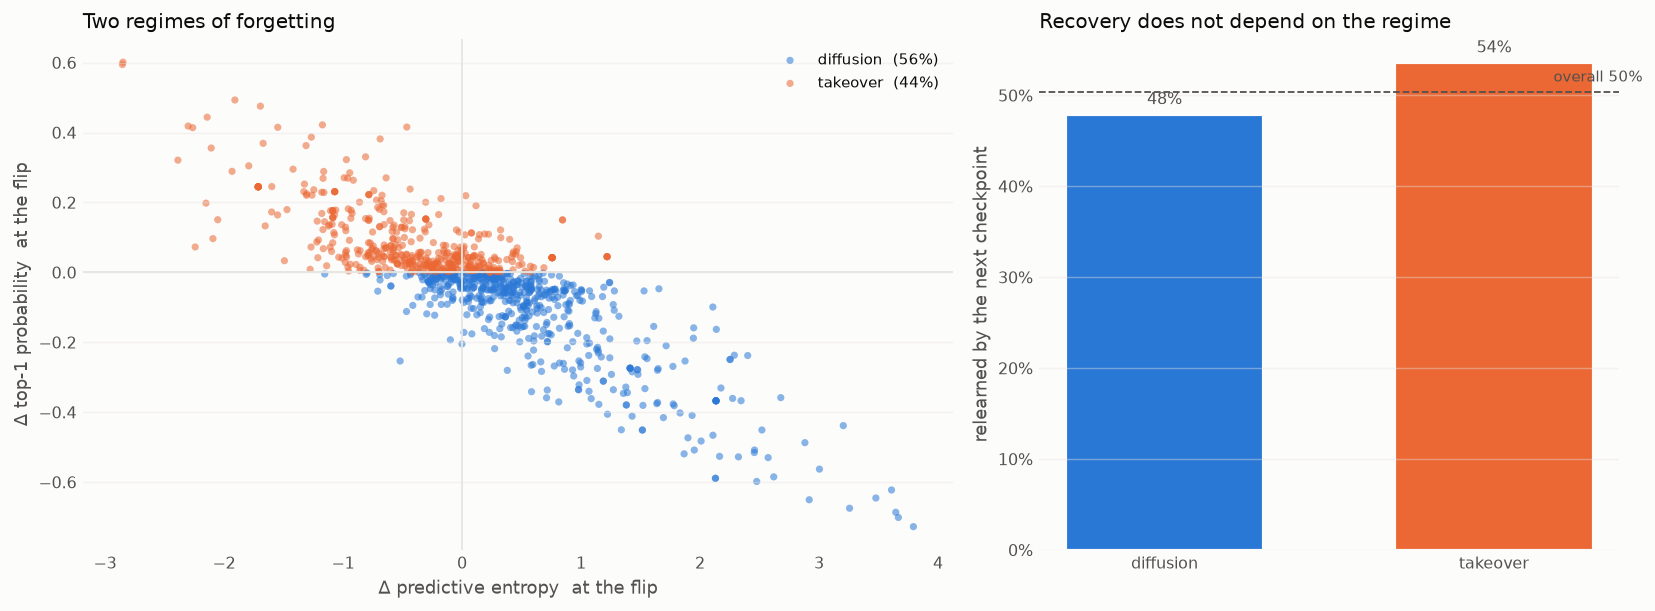

In [14]:
# §9 — decay vs takeover at the flip  (Kotha et al. 2024; Chang et al. 2024)
ev_f, ev_t = np.where(correct[:, :-1] & ~correct[:, 1:])       # (fact, step) of each event
d_top1 = NEWP["top1_prob"][ev_f, ev_t + 1] - NEWP["top1_prob"][ev_f, ev_t]
d_ent  = NEWP["pred_entropy"][ev_f, ev_t + 1] - NEWP["pred_entropy"][ev_f, ev_t]
takeover = d_top1 > 0

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12.8, 4.8),
                               gridspec_kw={"width_ratios": [1.5, 1]})
ax1.axhline(0, color=GRID, lw=1); ax1.axvline(0, color=GRID, lw=1)
ax1.scatter(d_ent[~takeover], d_top1[~takeover], s=16, color=BLUE, alpha=.55,
            edgecolor="none", label=f"diffusion  ({(~takeover).mean():.0%})")
ax1.scatter(d_ent[takeover], d_top1[takeover], s=16, color=ORANGE, alpha=.55,
            edgecolor="none", label=f"takeover  ({takeover.mean():.0%})")
ax1.set_xlabel("Δ predictive entropy  at the flip")
ax1.set_ylabel("Δ top-1 probability  at the flip")
ax1.set_title("Two regimes of forgetting", loc="left")
ax1.legend(loc="upper right", fontsize=8.5)

# relearning by t+2, by regime
back = np.array([correct[f, t + 2] if t + 2 < n_steps else np.nan
                 for f, t in zip(ev_f, ev_t)], float)
bars = [("diffusion", np.nanmean(back[~takeover]), BLUE),
        ("takeover",  np.nanmean(back[takeover]),  ORANGE)]
ax2.bar([b[0] for b in bars], [b[1] for b in bars],
        color=[b[2] for b in bars], edgecolor=SURF, linewidth=1.2, width=.6)
for i, b in enumerate(bars):
    ax2.text(i, b[1] + .012, f"{b[1]:.0%}", ha="center", fontsize=9, color=INK2)
ax2.axhline(np.nanmean(back), color=INK2, ls="--", lw=1)
ax2.text(1.45, np.nanmean(back) + .012, f"overall {np.nanmean(back):.0%}",
         ha="right", fontsize=8.5, color=INK2)
ax2.yaxis.set_major_formatter(plt.FuncFormatter(pfmt))
ax2.set_ylabel("relearned by the next checkpoint")
ax2.set_title("Recovery does not depend on the regime", loc="left")

for ax in (ax1, ax2):
    ax.grid(axis="y", alpha=.4); ax.tick_params(length=0)
    for s_ in ax.spines.values(): s_.set_visible(False)
fig.tight_layout()

print(f"{len(ev_f)} forgetting events")
print(f"  takeover  (top-1 rises): {takeover.mean():5.1%}  "
      f"median Δtop1={np.median(d_top1[takeover]):+.4f}  Δentropy={np.median(d_ent[takeover]):+.3f}")
print(f"  diffusion (top-1 falls): {(~takeover).mean():5.1%}  "
      f"median Δtop1={np.median(d_top1[~takeover]):+.4f}  Δentropy={np.median(d_ent[~takeover]):+.3f}")
print(f"  overall median Δentropy at the flip: {np.median(d_ent):+.3f}  (> 0 ⇒ net flattening)")
print(f"  relearned by t+2: overall {np.nanmean(back):.1%} | "
      f"takeover {np.nanmean(back[takeover]):.1%} vs diffusion {np.nanmean(back[~takeover]):.1%}")


**Result — both mechanisms are present, with diffusion the majority.** Of 1003
forgetting events, **44% are takeovers** (top-1 probability rises by a median
+0.050 while entropy *falls* 0.42 nats — a specific competitor is promoted) and
**56% are diffusion** (top-1 falls, entropy rises 0.46 nats). Net entropy change is
mildly positive (+0.10), so the aggregate picture is flattening, but averaging over
the two regimes hides the fact that nearly half of all forgetting is Kotha-style
**competition, not decay**.

Interestingly the regime does **not** predict recovery: 54% of takeovers and 48% of
diffusion events are correct again two checkpoints later (overall 50%). Whatever
distinguishes a permanent loss from a temporary dip, it is not which of these two
mechanisms produced the flip. That half of all forgetting events reverse within one
checkpoint is itself worth stating — this is oscillation around a threshold much
more than it is erasure.

## 10 — A noise floor: is "forgetting" just a stochastic read-out?

**Papers:** Toneva et al. (2019) (the *unforgettable examples* baseline); Maini et
al. (2022), *Characterizing Datapoints via Second-Split Forgetting* (NeurIPS).

This is the test that the rest of the notebook most needs, because §2 and §5 are
vulnerable to a deflationary reading. `correct` is a lenient substring match on a
greedy generation. If correctness were simply a **noisy sample** from the model's
answer distribution, then facts with low gold probability would flip back and forth
*by construction*, and "forgetting strikes fragile facts" would be a restatement of
"a coin weighted 0.1 comes up tails a lot" — no learning dynamics required.

The null model makes this precise. Calibrate P(correct | gold probability) on all
(fact, checkpoint) observations, then **resample every observation independently**
from that calibration, keeping each fact's real gold-probability trajectory. This
null has, by construction, the same relationship between confidence and correctness
as the real data — it differs *only* in having no memory from one checkpoint to the
next. Comparing the resulting **dynamics** isolates what the scalar cannot explain.

calibration AUC (gold_prob → correct): 0.757



                                observed  null mean          null 95% CI
hazard                             0.241      0.601   [0.586, 0.617]
P(still wrong t+2)                 0.497      0.652   [0.635, 0.670]
mean flips/fact                    1.802      4.010   [3.918, 4.112]
frac never flipping                0.469      0.104   [0.090, 0.118]


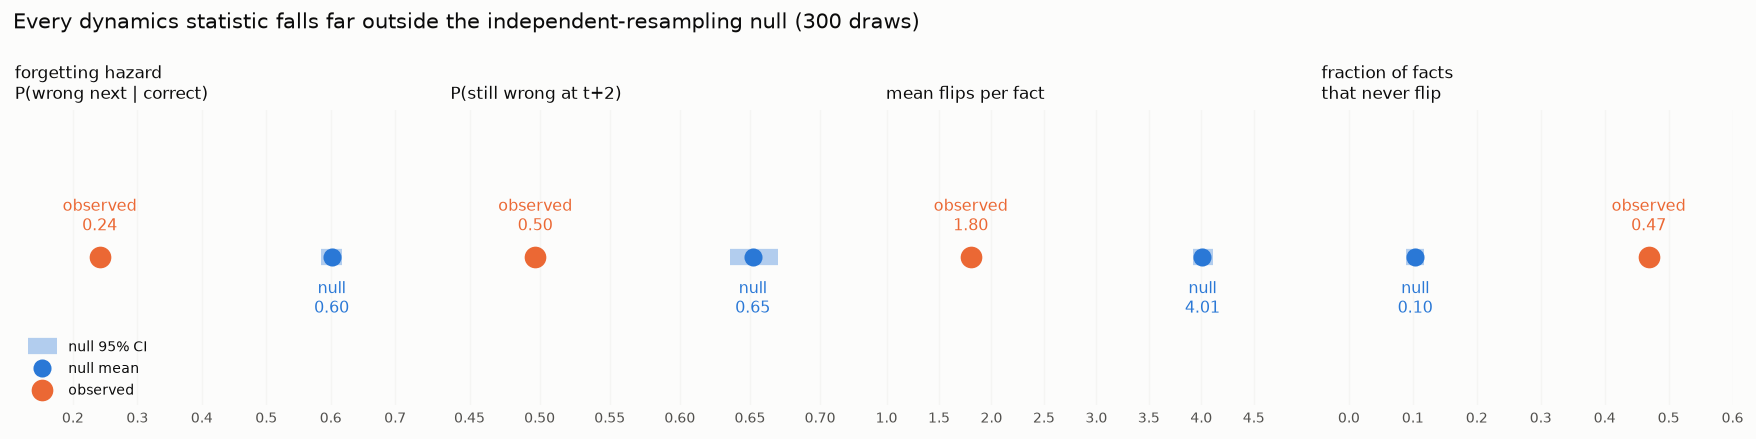

In [15]:
# §10 — noise-floor null  (Toneva et al. 2019; Maini et al. 2022)
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

lp = np.log10(np.clip(gp_mat, 1e-9, 1))
obsm = np.isfinite(lp)
Xc = np.column_stack([lp[obsm], lp[obsm] ** 2])
cal = LogisticRegression(max_iter=1000).fit(Xc, correct[obsm])
phat = np.zeros_like(gp_mat)
phat[obsm] = cal.predict_proba(Xc)[:, 1]
print(f"calibration AUC (gold_prob → correct): {roc_auc_score(correct[obsm], phat[obsm]):.3f}")

def dynamics(C):
    """Four summaries of the *temporal* structure of a correctness matrix."""
    haz = (C[:, :-1] & ~C[:, 1:]).sum() / max(C[:, :-1].sum(), 1)
    pers = [~C[C[:, t] & ~C[:, t + 1], t + 2] for t in range(n_steps - 2)
            if (C[:, t] & ~C[:, t + 1]).any()]
    flips = (C[:, 1:] != C[:, :-1]).sum(1)
    return (haz, np.mean(np.concatenate(pers)), flips.mean(), (flips == 0).mean())

rng = np.random.default_rng(0)
observed = dynamics(correct)
null = np.array([dynamics(rng.random(gp_mat.shape) < phat) for _ in range(300)])

LABELS = ["forgetting hazard\nP(wrong next | correct)", "P(still wrong at t+2)",
          "mean flips per fact", "fraction of facts\nthat never flip"]
# The null is extremely tight, so a histogram renders as a hairline: show each
# metric as observed vs null-mean dots with the null 95% CI drawn as a bar.
fig, axes = plt.subplots(1, 4, figsize=(13.6, 3.4))
for i, (ax, lab) in enumerate(zip(axes, LABELS)):
    lo_n, hi_n = np.percentile(null[:, i], [2.5, 97.5])
    ax.hlines(0, lo_n, hi_n, color=BLUE, lw=9, alpha=.35,
              zorder=1, label="null 95% CI")
    ax.plot(null[:, i].mean(), 0, "o", color=BLUE, ms=9, zorder=2, label="null mean")
    ax.plot(observed[i], 0, "o", color=ORANGE, ms=11, zorder=3, label="observed")
    lo_x = min(observed[i], lo_n); hi_x = max(observed[i], hi_n)
    pad = (hi_x - lo_x) * 0.35 + 1e-6
    ax.set_xlim(lo_x - pad, hi_x + pad)
    ax.annotate(f"observed\n{observed[i]:.2f}", (observed[i], 0), color=ORANGE,
                fontsize=9, ha="center", va="bottom", xytext=(0, 12),
                textcoords="offset points")
    ax.annotate(f"null\n{null[:, i].mean():.2f}", (null[:, i].mean(), 0), color=BLUE,
                fontsize=9, ha="center", va="top", xytext=(0, -12),
                textcoords="offset points")
    ax.set_ylim(-1, 1); ax.set_yticks([])
    ax.set_title(lab, loc="left", fontsize=9.5)
    ax.tick_params(length=0, labelsize=8); ax.grid(axis="x", alpha=.3)
    for s_ in ax.spines.values(): s_.set_visible(False)
axes[0].legend(loc="lower left", fontsize=8, ncol=1, bbox_to_anchor=(0, -0.02))
fig.suptitle("Every dynamics statistic falls far outside the independent-resampling null "
             "(300 draws)", x=0.01, ha="left", fontsize=11.5)
fig.tight_layout()

print(f"\n{'':30s} {'observed':>9s} {'null mean':>10s} {'null 95% CI':>20s}")
for i, lab in enumerate(["hazard", "P(still wrong t+2)", "mean flips/fact", "frac never flipping"]):
    lo_n, hi_n = np.percentile(null[:, i], [2.5, 97.5])
    print(f"{lab:30s} {observed[i]:9.3f} {null[:, i].mean():10.3f}   [{lo_n:.3f}, {hi_n:.3f}]")


**Result — the deflationary reading is decisively rejected, and in the direction
that strengthens the project's thesis.** The null reproduces the confidence
↔ correctness relationship exactly (calibration AUC 0.757) but has no memory across
checkpoints, and its dynamics are nothing like the observed ones:

| | observed | null (95% CI) |
|---|---|---|
| forgetting hazard | **0.241** | 0.601 [0.587, 0.616] |
| P(still wrong at t+2) | **0.497** | 0.652 [0.635, 0.670] |
| mean flips per fact | **1.80** | 4.01 [3.93, 4.10] |
| fraction of facts that never flip | **0.469** | 0.103 [0.089, 0.118] |

Every statistic is far outside the null interval. Real correctness is **2.2×
more persistent** than an independent read-out of the same gold probabilities would
be, and 47% of facts never flip at all against a null expectation of 10% — a direct
analogue of Toneva et al.'s *unforgettable examples*, and evidence that a fact's
state carries information the final-layer scalar does not.

Two consequences. (1) "Forgetting strikes fragile facts" survives — it is not an
artefact of stochastic scoring. (2) But the same result says gold probability is a
**badly incomplete** description of a fact's state, which is precisely why the
representation-level features in the companion notebook can beat it, and why §8's
mid-stack signal exists at all.

## 11 — Further tests worth running (not run here)

Ordered by expected value per unit of work. The first needs no new extraction; the
rest do.

**11a — Forgetting vs. time since last exposure.** *Leans on:* Chang et al. (2024);
Jagielski et al. (2023), *Measuring Forgetting of Memorized Training Examples*
(ICLR); Tirumala et al. (2022). The single biggest gap in this analysis is that it
never asks *why forgetting happens at that checkpoint*. LMEnt makes the training
order fully observable: `src/schedule.py build_chunk_to_steps()` inverts the real
`batch_indices`, so each fact's `shared_chunks` map to the exact steps where its
evidence appeared. Because LMEnt-1B is a **6-epoch** run, every chunk recurs once
per epoch — a natural experiment. Test: model the forgetting hazard as a function
of (i) steps elapsed since the fact's most recent supporting chunk and (ii) the
count of *interfering* appearances (subject-only or answer-only, which
`src/features/competition.py` already computes), controlling for gold probability.
A positive recency effect would turn the descriptive "fragile facts flip" into a
causal account. **This is the test I would run next.**

**11b — Second-split forgetting time as a fact taxonomy.** *Leans on:* Maini et al.
(2022). Rather than counting events, record for each fact the *first* checkpoint at
which it is learned and the *first* at which it is lost. Maini et al. show the
learn/forget timing pair separates rare-but-real examples from mislabelled ones —
here it should separate genuinely low-exposure facts from facts whose PopQA gold
answer is contested or alias-dependent, which is a known noise source in this
evaluation.

**11c — Tuned lens instead of logit lens.** *Leans on:* Belrose et al. (2023). §8's
early- and final-layer numbers are affected by the raw logit lens's known bias.
Fitting the affine tuned-lens probe per layer per checkpoint would confirm the
layer-12 divergence and remove the layer-18 artefact. Needs the checkpoints and a
GPU, but it is a small fit.

**11d — Causal cross-checkpoint activation patching.** *Leans on:* Meng et al.
(2022) (causal tracing); Zhang & Nanda (2024), *Towards Best Practices of Activation
Patching*. Everything in both notebooks is correlational. The decisive experiment:
take a fact forgotten between checkpoint *t* and *t+1*, run the *t+1* model, and
patch in the *t* model's activations one layer at a time. The layer that restores
the correct answer *is* the locus of forgetting. §8 predicts layers 10–13. This
requires both checkpoints resident on GPU but is otherwise standard.

**11e — Does the competitor come from the few-shot prompt?** *Leans on:* Kotha et
al. (2024); Min et al. (2022), *Rethinking the Role of Demonstrations*. For the 44%
of events that are takeovers (§9), check whether the winning token appears in the
15-shot prompt. If forgetting is partly the model falling back on the demonstration
distribution, the takeover answers should be drawn from the exemplars far more often
than chance. The `prompt` and `generation` columns are already stored — this is a
string-matching job and could be done without touching a GPU.

## 12 — Does the forgetting rate really rise with fact frequency?

**Papers:** Kandpal et al. (2023), *Large Language Models Struggle to Learn Long-Tail
Knowledge* (ICML); Mallen et al. (2023), *When Not to Trust Language Models* (ACL);
Chang et al. (2024), *How Do Large Language Models Acquire Factual Knowledge During
Pretraining?* (NeurIPS); Toneva et al. (2019).

This section tests a premise the project has been carrying: **that facts seen more
often are forgotten more.** It matters because it would be genuinely surprising —
Kandpal et al. and Mallen et al. both find that co-occurrence frequency *drives*
factual recall, and Chang et al. find that duplication makes acquired knowledge
**more** durable, not less. If LMEnt showed the opposite, that would be the headline
of the project.

The test needs care on two points.

**(1) "Frequency" is not one variable.** The joined `competition_df.parquet` splits it:

| variable | meaning |
|---|---|
| `num_shared_chunks` | chunks stating the fact — **evidence for this fact** |
| `total_subj_chunks` | chunks mentioning the subject at all — **subject popularity** |
| `chunks_ratio` | shared / total — **purity** of the subject's evidence |
| `num_competitive_facts` | facts sharing this fact's `competitive_word` — **competition** |

These pull apart: `num_shared_chunks` and `total_subj_chunks` correlate only 0.34,
and `num_competitive_facts` correlates **+0.65** with subject popularity but
**−0.23** with the fact's own evidence.

**(2) Count is not rate.** A fact can only be forgotten at a checkpoint where it is
currently correct. High-frequency facts are correct far more often, so they have far
more *opportunities* to be forgotten. Counting events (Toneva et al.'s forgetting
count) and measuring the hazard P(wrong next | correct now) can therefore point in
opposite directions. That distinction turns out to be the whole story.

In [16]:
# §12 — load the competition/frequency features and align them to the panel
comp = pd.read_parquet("competition_df.parquet")
freq = (props.reset_index().merge(comp, on="id", how="left").set_index("id").reindex(ids))
shared_n = freq["num_shared_chunks"].to_numpy(float)     # evidence for the fact
subj_tot = freq["total_subj_chunks"].to_numpy(float)     # subject popularity
purity   = freq["chunks_ratio"].to_numpy(float)          # shared / total
n_comp   = freq["num_competitive_facts"].to_numpy(float) # competing facts

FREQ_VARS = [("num_shared_chunks\n(evidence for the fact)", shared_n),
             ("total_subj_chunks\n(subject popularity)",    subj_tot),
             ("chunks_ratio\n(evidence purity)",            purity),
             ("num_competitive_facts\n(competition)",       n_comp)]

# transition-aligned copies
tfa, tta, tfga = [], [], []
for t in range(n_steps - 1):
    i = np.where(correct[:, t])[0]
    tfa.append(i); tta.append(np.full(i.size, t)); tfga.append(~correct[i, t + 1])
TFa, TTa, TFGa = np.concatenate(tfa), np.concatenate(tta), np.concatenate(tfga).astype(bool)
print(f"{TFGa.size} correct→next transitions, base forgetting rate {TFGa.mean():.1%}")
print(f"log-scale correlations among the four frequency variables:")
_L = pd.DataFrame({n.split(chr(10))[0]: np.log1p(v) if v.max() > 1 else v
                   for n, v in FREQ_VARS})
print(_L.corr().round(2).to_string())


4154 correct→next transitions, base forgetting rate 24.1%
log-scale correlations among the four frequency variables:
                       num_shared_chunks  total_subj_chunks  chunks_ratio  num_competitive_facts
num_shared_chunks                   1.00               0.36          0.08                  -0.24
total_subj_chunks                   0.36               1.00         -0.63                   0.63
chunks_ratio                        0.08              -0.63          1.00                  -0.47
num_competitive_facts              -0.24               0.63         -0.47                   1.00


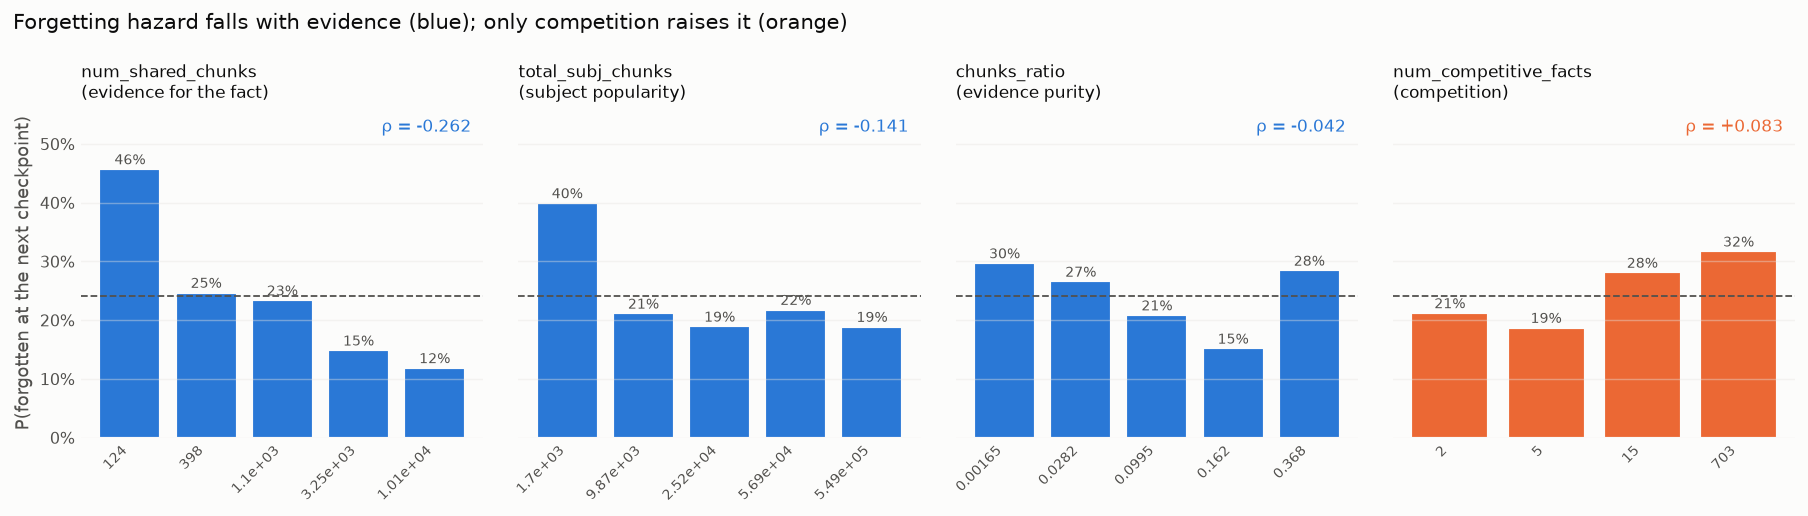

Spearman ρ(variable, forgotten-next), and the same ρ computed *within* gold-probability strata:
  num_shared_chunks        ρ = -0.262   within-gold_prob mean ρ = -0.199
  total_subj_chunks        ρ = -0.141   within-gold_prob mean ρ = -0.120
  chunks_ratio             ρ = -0.042   within-gold_prob mean ρ = -0.028
  num_competitive_facts    ρ = +0.083   within-gold_prob mean ρ = +0.037


In [17]:
# §12a — forgetting HAZARD against each notion of frequency
from scipy.stats import spearmanr

fig, axes = plt.subplots(1, 4, figsize=(14, 4.0), sharey=True)
for ax, (name, v) in zip(axes, FREQ_VARS):
    vt = v[TFa]
    q = pd.qcut(vt, 5, labels=False, duplicates="drop")
    haz = np.array([TFGa[q == i].mean() for i in range(q.max() + 1)])
    med = [np.median(vt[q == i]) for i in range(q.max() + 1)]
    rho, pv = spearmanr(vt, TFGa)
    up = rho > 0
    ax.bar(range(len(haz)), haz, color=ORANGE if up else BLUE,
           edgecolor=SURF, linewidth=1.2)
    for i, h in enumerate(haz):
        ax.text(i, h + .008, f"{h:.0%}", ha="center", fontsize=8, color=INK2)
    ax.axhline(TFGa.mean(), color=INK2, ls="--", lw=1)
    ax.set_xticks(range(len(haz)), [f"{m:.3g}" for m in med], rotation=45, ha="right", fontsize=7.5)
    ax.set_title(name, loc="left", fontsize=9.5)
    ax.annotate(f"ρ = {rho:+.3f}", (0.97, 0.97), xycoords="axes fraction",
                ha="right", va="top", fontsize=9.5, color=ORANGE if up else BLUE)
    ax.set_ylim(0, 0.56)
    ax.grid(axis="y", alpha=.4); ax.tick_params(length=0)
    for s_ in ax.spines.values(): s_.set_visible(False)
axes[0].yaxis.set_major_formatter(plt.FuncFormatter(pfmt))
axes[0].set_ylabel("P(forgotten at the next checkpoint)")
fig.suptitle("Forgetting hazard falls with evidence (blue); only competition raises it (orange)",
             x=0.01, ha="left", fontsize=11.5)
fig.tight_layout(); plt.show()

print("Spearman ρ(variable, forgotten-next), and the same ρ computed *within* gold-probability strata:")
gq = pd.qcut(NEWP["gold_prob"][TFa, TTa], 5, labels=False, duplicates="drop")
for name, v in FREQ_VARS:
    vt = v[TFa]
    within = [spearmanr(vt[gq == g], TFGa[gq == g])[0] for g in range(gq.max() + 1)
              if (gq == g).sum() > 50 and len(np.unique(TFGa[gq == g])) > 1]
    print(f"  {name.split(chr(10))[0]:24s} ρ = {spearmanr(vt, TFGa)[0]:+.3f}   "
          f"within-gold_prob mean ρ = {np.mean(within):+.3f}")


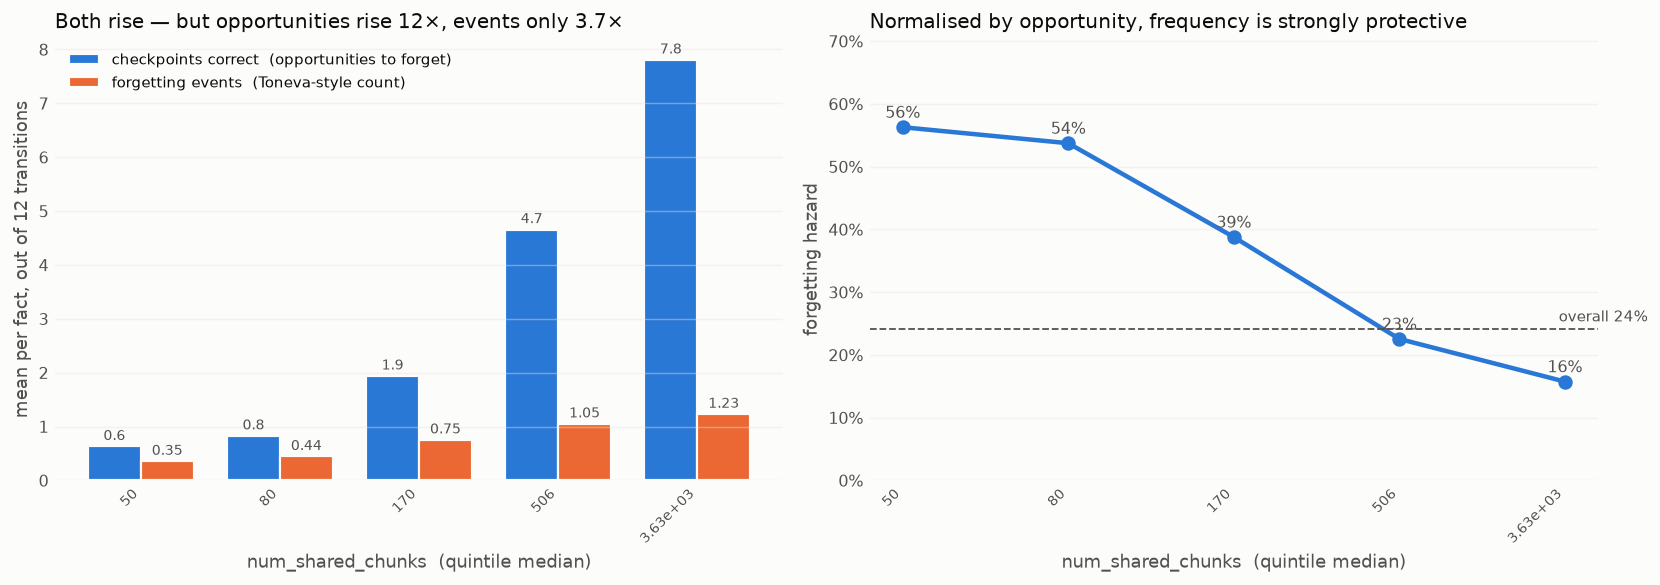

 quintile  med shared   #events  #correct   hazard
        0          50      0.35      0.63    56.3%
        1          80      0.44      0.83    53.7%
        2         170      0.75      1.94    38.8%
        3         506      1.05      4.66    22.5%
        4        3628      1.23      7.81    15.7%

hazard restricted to observations where the gold answer IS top-1 (removes lenient-substring luck):
   Q0: 28.9%  Q1: 20.5%  Q2: 19.3%  Q3: 13.7%  Q4: 10.6%


In [18]:
# §12b — the paradox: event COUNT rises with frequency while the RATE falls
n_events = (correct[:, :-1] & ~correct[:, 1:]).sum(1)      # Toneva-style forgetting count
n_opps   = correct[:, :-1].sum(1)                          # checkpoints at risk
qe = pd.qcut(shared_n, 5, labels=False, duplicates="drop")
med_sh = [np.median(shared_n[qe == i]) for i in range(qe.max() + 1)]
ev  = np.array([n_events[qe == i].mean() for i in range(qe.max() + 1)])
opp = np.array([n_opps[qe == i].mean() for i in range(qe.max() + 1)])
hz  = np.array([n_events[qe == i].sum() / max(n_opps[qe == i].sum(), 1)
                for i in range(qe.max() + 1)])

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12.8, 4.6))
w = 0.38; xq = np.arange(len(ev))
ax1.bar(xq - w/2, opp, w, color=BLUE, edgecolor=SURF, linewidth=1.2,
        label="checkpoints correct  (opportunities to forget)")
ax1.bar(xq + w/2, ev, w, color=ORANGE, edgecolor=SURF, linewidth=1.2,
        label="forgetting events  (Toneva-style count)")
for i in range(len(ev)):
    ax1.text(i - w/2, opp[i] + .12, f"{opp[i]:.1f}", ha="center", fontsize=8, color=INK2)
    ax1.text(i + w/2, ev[i] + .12, f"{ev[i]:.2f}", ha="center", fontsize=8, color=INK2)
ax1.set_xticks(xq, [f"{m:.3g}" for m in med_sh], rotation=45, ha="right", fontsize=8)
ax1.set_xlabel("num_shared_chunks  (quintile median)")
ax1.set_ylabel("mean per fact, out of 12 transitions")
ax1.set_title("Both rise — but opportunities rise 12×, events only 3.7×", loc="left")
ax1.legend(loc="upper left", fontsize=8.5)

ax2.plot(xq, hz, color=BLUE, lw=2.5, marker="o", ms=7)
for i, h in enumerate(hz):
    ax2.text(i, h + .015, f"{h:.0%}", ha="center", fontsize=9, color=INK2)
ax2.axhline(TFGa.mean(), color=INK2, ls="--", lw=1)
ax2.text(len(hz) - .5, TFGa.mean() + .012, f"overall {TFGa.mean():.0%}",
         ha="right", fontsize=8.5, color=INK2)
ax2.set_xticks(xq, [f"{m:.3g}" for m in med_sh], rotation=45, ha="right", fontsize=8)
ax2.yaxis.set_major_formatter(plt.FuncFormatter(pfmt))
ax2.set_xlabel("num_shared_chunks  (quintile median)")
ax2.set_ylabel("forgetting hazard")
ax2.set_ylim(0, max(hz) * 1.25)
ax2.set_title("Normalised by opportunity, frequency is strongly protective", loc="left")
for ax in (ax1, ax2):
    ax.grid(axis="y", alpha=.4); ax.tick_params(length=0)
    for s_ in ax.spines.values(): s_.set_visible(False)
fig.tight_layout(); plt.show()

print(f"{'quintile':>9s} {'med shared':>11s} {'#events':>9s} {'#correct':>9s} {'hazard':>8s}")
for i in range(len(ev)):
    print(f"{i:>9d} {med_sh[i]:>11.0f} {ev[i]:>9.2f} {opp[i]:>9.2f} {hz[i]:>8.1%}")

# robustness: restrict to observations where gold really is the top-1 token
t1 = NEWP["top1_prob"][TFa, TTa] > 0                      # placeholder guard
is_t1 = P["is_top1"].to_numpy()[TFa, TTa].astype(bool)
qt = pd.qcut(shared_n[TFa], 5, labels=False, duplicates="drop")
print("\nhazard restricted to observations where the gold answer IS top-1 "
      "(removes lenient-substring luck):")
print("   " + "  ".join(f"Q{i}: {TFGa[(qt == i) & is_t1].mean():.1%}" for i in range(qt.max() + 1)))


**Result — the premise is not just unsupported, it is inverted.** The forgetting
*hazard* falls steeply and monotonically with the evidence for a fact: from **46%**
in the lowest `num_shared_chunks` quintile to **12%** in the highest (Spearman
ρ = −0.262, p ≈ 1e-63). Subject popularity is also protective (40% → 19%,
ρ = −0.141). Only **competition** goes the other way: `num_competitive_facts` is the
single frequency-like variable where more means more forgetting (21% → 32%,
ρ = +0.083).

This is not a selection artefact. The negative relationship survives:

- **controlling for how well the fact is currently stored** — the mean within-
  gold-probability-stratum ρ is still **−0.199** for `num_shared_chunks`;
- **restricting to observations where the gold answer is genuinely top-1**, which
  removes facts that were "correct" only through lenient substring matching: the
  hazard still falls **28.9% → 10.6%** across quintiles.

**Where the opposite impression comes from.** Panel 12b shows it directly. The
*number* of forgetting events per fact does rise with frequency — **0.35 → 1.23**,
which is what one sees plotting Toneva-style forgetting counts against exposure. But
the number of checkpoints at which a fact is correct at all rises far faster,
**0.63 → 7.81**. Rare facts are almost never correct, so they can hardly ever be
*observed* to forget; frequent facts are correct most of the time and therefore
accumulate events. Events rise 3.5×, opportunities rise 12.4×, so dividing one by
the other reverses the sign: the hazard goes **56% → 16%**.

So the correct statement for the project is:

> **Frequency protects against forgetting.** What rises with frequency is the raw
> count of forgetting events, driven entirely by the number of opportunities. The
> variable that genuinely increases the forgetting *rate* is not frequency but
> **competition** — how many other facts share the subject's competitive word.

Two caveats worth carrying. This dataset is the **top-10% exposure** slice, so even
the lowest quintile has ≥ 42 supporting chunks — the true long tail is not sampled,
and Kandpal et al.'s regime of near-zero exposure lies outside it. And `chunks_ratio`
(evidence purity) is non-monotonic, so the clean story is about absolute evidence,
not the signal-to-noise of a subject's mentions.

This aligns LMEnt with Kandpal et al. (2023) and Mallen et al. (2023) on the recall
side and with Chang et al. (2024) on the durability side, rather than contradicting
them. The competition result is the thread pulled on in the companion notebook,
§§17–18.